<a href="https://colab.research.google.com/github/Shorupar/Nagarik_Sathi_AI/blob/main/ai_recruitment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Requirements

In [ ]:
# Add necessary dependencies to requirements.txt (to be updated with each new library used)

%%writefile requirements.txt
kagglehub[pandas-datasets]>=1.0.2,<2.0.0
pandas>=2.2.3,<3.0.0
numpy>=2.1.3,<3.0.0
scikit-learn>=1.6.1,<2.0.0
sentence-transformers>=5.7.0,<6.0.0
gradio>=6.29.0,<7.0.0
seaborn>=0.13.2,<0.14.0
matplotlib>=3.10.0,<3.11.0
datasets>=4.8.5

Writing requirements.txt


In [ ]:
# Install project dependencies listed in requirements.txt

%pip install -r requirements.txt

## README

### **Recruitment AI**

A work in progress Google Colab resume evaluation application developed by the EARTech Information Technology interns. The project is currently being developed and tested in Google Colab.

#### **Overview**

Recruitment AI aims to evaluate how well a candidate's resume matches a given job description.

Users will be able to submit their resume, a job description, and a list of required and preferred skills for the role. Upon clicking Analyze, the application will process the submitted information and generate an evaluation of how closely the candidate's qualifications match the job requirements.

#### **Tech Stack**

- **Python:**
  - **Data processing**: pandas, numpy
  - **Dataset Access:** KaggleHub
  - **Machine Learning & Text Feature Extraction:** scikit-learn
  - **Semantic Text Embeddings:** Sentence Transformers
  - **Data Visualization:** matplotlib, seaborn
  - **User Interface:** Gradio (planned)
- **Google Colab:** Development and experimentation.

#### **How to run Recruitment AI**
1. Open the notebook in Google Colab.
2. Run the **Requirements** cells to create `requirements.txt` and install the dependencies.
3. If Kaggle access is required, authenticate `kagglehub` using Colab Secrets. Never paste keys into the notebook.
4. Run **Runtime → Run all**. Day 1 loads and cleans the data, Day 2 builds TF-IDF, embeddings and similarity scores, and Day 3 adds configurable scoring, skill gaps, ranking and explanations.
5. Outputs are written to `/content/cleaned_data/` (cosine scores, similarity results, error log, ranking, explanations, evaluation table and checkpoint report).
6. The first run downloads the datasets and the embedding model, so it can take several minutes.

The Gradio interface is planned and not yet available.

#### **Rules**
- Synthetic data only. No real names, emails or customer data.
- No keys, tokens or passwords in code or the data.



# Day 1


 ## Candidate JSONL

In [ ]:
import pandas as pd

# Load resumes from Hugging Face and assign to the expected variable name
candidate_df = pd.read_json("hf://datasets/datasetmaster/resumes/master_resumes.jsonl", lines=True)

print(f"Candidate dataset loaded successfully! Total rows: {len(candidate_df)}")

Candidate dataset loaded successfully! Total rows: 4817


## Job CSV

In [ ]:
import kagglehub
import pandas as pd
import os

# Download latest version of job descriptions from Kaggle
job_path = kagglehub.dataset_download("ravindrasinghrana/job-description-dataset")
print("Path to dataset files:", job_path)

# Find the CSV file inside the downloaded folder and load it
csv_files = [f for f in os.listdir(job_path) if f.endswith('.csv')]

if csv_files:
    # Load the first CSV file found into jobs_df
    csv_file_path = os.path.join(job_path, csv_files[0])
    jobs_df = pd.read_csv(csv_file_path)
    print(f"Job dataset loaded successfully! Total rows: {len(jobs_df)}")
else:
    print("Error: No CSV file found in the downloaded dataset.")

Using Colab cache for faster access to the 'job-description-dataset' dataset.
Path to dataset files: /kaggle/input/job-description-dataset
Job dataset loaded successfully! Total rows: 1615940


In [ ]:
# Display the first 5 rows of the jobs dataset
jobs_df.head()

,Job Id,Experience,Qualifications,Salary Range,location,Country,latitude,longitude,Work Type,Company Size,...,Contact,Job Title,Role,Job Portal,Job Description,Benefits,skills,Responsibilities,Company,Company Profile
0,1089843540111562,5 to 15 Years,M.Tech,$59K-$99K,Douglas,Isle of Man,54.2361,-4.5481,Intern,26801,...,001-381-930-7517x737,Digital Marketing Specialist,Social Media Manager,Snagajob,Social Media Managers oversee an organizations...,"{'Flexible Spending Accounts (FSAs), Relocatio...","Social media platforms (e.g., Facebook, Twitte...","Manage and grow social media accounts, create ...",Icahn Enterprises,"{""Sector"":""Diversified"",""Industry"":""Diversifie..."
1,398454096642776,2 to 12 Years,BCA,$56K-$116K,Ashgabat,Turkmenistan,38.9697,59.5563,Intern,100340,...,461-509-4216,Web Developer,Frontend Web Developer,Idealist,Frontend Web Developers design and implement u...,"{'Health Insurance, Retirement Plans, Paid Tim...","HTML, CSS, JavaScript Frontend frameworks (e.g...","Design and code user interfaces for websites, ...",PNC Financial Services Group,"{""Sector"":""Financial Services"",""Industry"":""Com..."
2,481640072963533,0 to 12 Years,PhD,$61K-$104K,Macao,"Macao SAR, China",22.1987,113.5439,Temporary,84525,...,9687619505,Operations Manager,Quality Control Manager,Jobs2Careers,Quality Control Managers establish and enforce...,"{'Legal Assistance, Bonuses and Incentive Prog...",Quality control processes and methodologies St...,Establish and enforce quality control standard...,United Services Automobile Assn.,"{""Sector"":""Insurance"",""Industry"":""Insurance: P..."
3,688192671473044,4 to 11 Years,PhD,$65K-$91K,Porto-Novo,Benin,9.3077,2.3158,Full-Time,129896,...,+1-820-643-5431x47576,Network Engineer,Wireless Network Engineer,FlexJobs,"Wireless Network Engineers design, implement, ...","{'Transportation Benefits, Professional Develo...",Wireless network design and architecture Wi-Fi...,"Design, configure, and optimize wireless netwo...",Hess,"{""Sector"":""Energy"",""Industry"":""Mining, Crude-O..."
4,117057806156508,1 to 12 Years,MBA,$64K-$87K,Santiago,Chile,-35.6751,-71.5429,Intern,53944,...,343.975.4702x9340,Event Manager,Conference Manager,Jobs2Careers,A Conference Manager coordinates and manages c...,"{'Flexible Spending Accounts (FSAs), Relocatio...",Event planning Conference logistics Budget man...,Specialize in conference and convention planni...,Cairn Energy,"{""Sector"":""Energy"",""Industry"":""Energy - Oil & ..."


In [ ]:
# Display the first 5 rows of the candidate dataset
candidate_df.head()

,personal_info,experience,education,skills,projects,certifications,achievements,workshops,publications,teaching_experience,internships
0,"{'name': 'Unknown', 'email': 'Unknown', 'phone...","[{'company': 'Fresher', 'company_info': {'indu...","[{'degree': {'level': 'ME', 'field': 'Computer...",{'technical': {'programming_languages': [{'nam...,"[{'name': 'Unknown', 'description': 'Unknown',...",,NaN,NaN,NaN,NaN,NaN
1,"{'name': 'Unknown', 'email': 'Unknown', 'phone...","[{'company': 'Delta Controls, Dubai FZCO', 'co...","[{'degree': {'level': 'B.E', 'field': 'Electro...",{'technical': {'project_management': [{'name':...,"[{'name': 'FGP/WPMP', 'description': 'Led syst...",,NaN,NaN,NaN,NaN,NaN
2,"{'name': 'Not Provided', 'email': 'Not Provide...","[{'company': 'Parkar Consulting and Labs', 'co...","[{'degree': {'level': 'B.E.', 'field': 'Not Pr...",{'technical': {'programming_languages': [{'nam...,"[{'name': 'FPGA Implementation', 'description'...",,NaN,NaN,NaN,NaN,NaN
3,"{'name': 'Unknown', 'email': 'Unknown', 'phone...","[{'company': 'Delta Controls, Dubai FZCO', 'co...","[{'degree': {'level': 'B.E', 'field': 'Electro...",{'technical': {'project_management': [{'name':...,"[{'name': 'FGP/WPMP', 'description': 'Led syst...",,NaN,NaN,NaN,NaN,NaN
4,"{'name': '', 'email': '', 'phone': '', 'locati...","[{'company': 'Atos Syntel', 'company_info': {'...",[{'degree': {'level': 'Bachelor of Engineering...,{'technical': {'programming_languages': [{'nam...,[],"{""name"": ""ESD Program"", ""issuer"": ""Zensar Tech...","[Treasurer in IEEE student branch at JSCOE, Pu...","[{'name': 'Medical IoT', 'issuer': 'IEEE Stand...",NaN,NaN,NaN


## **Cleaning logic**

In [ ]:
def extract_preferred_skills(description, required_skills):
    """Extract skills mentioned in job description but not in required skills."""
    if not isinstance(description, str) or not description.strip():
        return []
    import re
    # Get required skills as a set
    req_set = set()
    if isinstance(required_skills, str):
        try:
            import ast
            req_set = set(s.lower() for s in ast.literal_eval(required_skills))
        except:
            req_set = set(s.strip().lower() for s in required_skills.split(','))
    elif isinstance(required_skills, (list,)):
        req_set = set(str(s).lower() for s in required_skills)
    # Extract words from description, filter out stop words and required
    stop_words = {'the', 'and', 'or', 'a', 'an', 'to', 'of', 'in', 'for', 'with', 'on', 'at', 'by', 'from', 'as', 'is', 'are', 'was', 'were', 'be', 'been', 'being', 'have', 'has', 'had', 'do', 'does', 'did', 'will', 'would', 'could', 'should', 'may', 'might', 'can', 'this', 'that', 'these', 'those', 'i', 'you', 'he', 'she', 'it', 'we', 'they', 'me', 'him', 'her', 'us', 'them', 'my', 'your', 'his', 'her', 'its', 'our', 'their', 'what', 'which', 'who', 'whom', 'where', 'when', 'why', 'how', 'all', 'each', 'every', 'both', 'few', 'more', 'most', 'other', 'some', 'such', 'no', 'nor', 'not', 'only', 'own', 'same', 'so', 'than', 'too', 'very', 'just', 'also'}
    words = re.findall(r'[a-zA-Z]+', description.lower())
    preferred = [w for w in words if len(w) > 2 and w not in stop_words and w not in req_set]
    return list(set(preferred))[:10]


def extract_education_level(education):
    """Map education to numeric level: PhD=4, Masters=3, Bachelors=2, Other=1."""
    if not education or not isinstance(education, (list, str)):
        return 1
    text = str(education).lower()
    if 'phd' in text or 'ph.d' in text or 'doctorate' in text:
        return 4
    if 'master' in text or 'm.s' in text or 'msc' in text or 'mba' in text or 'm.tech' in text:
        return 3
    if 'bachelor' in text or 'b.s' in text or 'bsc' in text or 'b.tech' in text or 'b.e' in text:
        return 2
    return 1


import pandas as pd
import os

def clean_candidate_data(df: pd.DataFrame) -> pd.DataFrame:
    """
    Keep only the essential columns from the candidate dataset based on raw columns.
    Raw: ['personal_info', 'experience', 'education', 'skills', 'projects', ...]
    """
    cleaned = pd.DataFrame()

    # Exact mapping based on your raw columns output
    cleaned['skills'] = df.get('skills', pd.Series([None]*len(df)))
    cleaned['projects'] = df.get('projects', pd.Series([None]*len(df)))
    cleaned['experience'] = df.get('experience', pd.Series([None]*len(df)))
    cleaned['education'] = df.get('education', pd.Series([None]*len(df)))

        # Extract education level from education field
    cleaned['education_level'] = df.get('education', pd.Series([None]*len(df))).apply(extract_education_level)

    return cleaned

def clean_jobs_data(df: pd.DataFrame) -> pd.DataFrame:
    """
    Keep only the essential columns from the jobs dataset based on raw columns.
    Raw: ['Job Title', 'skills', 'Qualifications', 'Responsibilities', ...]
    """
    cleaned = pd.DataFrame()

    # Exact mapping based on your raw columns output
    cleaned['role_title'] = df.get('Job Title', pd.Series([None]*len(df)))
    cleaned['required_skills'] = df.get('skills', pd.Series([None]*len(df)))
    cleaned['education_criteria'] = df.get('Qualifications', pd.Series([None]*len(df)))

    # Use 'Responsibilities' if available, otherwise fall back to 'Job Description'
    if 'Responsibilities' in df.columns:
        cleaned['responsibilities'] = df['Responsibilities']
    else:
        cleaned['responsibilities'] = df.get('Job Description', pd.Series([None]*len(df)))

        # Extract education level from education field
    cleaned['education_level'] = df.get('education', pd.Series([None]*len(df))).apply(extract_education_level)

    return cleaned

if __name__ == '__main__':
    print("Starting the simplified cleaning process with exact raw column names...")

    # Clean the datasets already loaded in memory
    cleaned_candidates = clean_candidate_data(candidate_df)
    cleaned_jobs = clean_jobs_data(jobs_df)

    # Inspect the results
    print('\n=== CANDIDATES ===')
    print(f'Shape: {cleaned_candidates.shape}')
    print(f'Columns: {list(cleaned_candidates.columns)}')

    print('\n=== JOBS ===')
    print(f'Shape: {cleaned_jobs.shape}')
    print(f'Columns: {list(cleaned_jobs.columns)}')

    # Save cleaned datasets to workspace
    os.makedirs('/content/cleaned_data', exist_ok=True)
    cleaned_candidates.to_csv('/content/cleaned_data/cleaned_candidates.csv', index=False)
    cleaned_jobs.to_csv('/content/cleaned_data/cleaned_jobs.csv', index=False)

    print('\nCleaned datasets saved successfully!')

Starting the simplified cleaning process with exact raw column names...

=== CANDIDATES ===
Shape: (4817, 5)
Columns: ['skills', 'projects', 'experience', 'education', 'education_level']

=== JOBS ===
Shape: (1615940, 5)
Columns: ['role_title', 'required_skills', 'education_criteria', 'responsibilities', 'education_level']

Cleaned datasets saved successfully!


In [ ]:
# Display the first 3 rows of the cleaned candidates
print("--- Cleaned Candidates Sample ---")
display(cleaned_candidates.head(3))

# Display the first 3 rows of the cleaned jobs
print("\n--- Cleaned Jobs Sample ---")
display(cleaned_jobs.head(3))

--- Cleaned Candidates Sample ---


,skills,projects,experience,education,education_level
0,{'technical': {'programming_languages': [{'nam...,"[{'name': 'Unknown', 'description': 'Unknown',...","[{'company': 'Fresher', 'company_info': {'indu...","[{'degree': {'level': 'ME', 'field': 'Computer...",2
1,{'technical': {'project_management': [{'name':...,"[{'name': 'FGP/WPMP', 'description': 'Led syst...","[{'company': 'Delta Controls, Dubai FZCO', 'co...","[{'degree': {'level': 'B.E', 'field': 'Electro...",2
2,{'technical': {'programming_languages': [{'nam...,"[{'name': 'FPGA Implementation', 'description'...","[{'company': 'Parkar Consulting and Labs', 'co...","[{'degree': {'level': 'B.E.', 'field': 'Not Pr...",2



--- Cleaned Jobs Sample ---


,role_title,required_skills,education_criteria,responsibilities,education_level
0,Digital Marketing Specialist,"Social media platforms (e.g., Facebook, Twitte...",M.Tech,"Manage and grow social media accounts, create ...",1
1,Web Developer,"HTML, CSS, JavaScript Frontend frameworks (e.g...",BCA,"Design and code user interfaces for websites, ...",1
2,Operations Manager,Quality control processes and methodologies St...,PhD,Establish and enforce quality control standard...,1


## **Skill** **taxonomy**


In [ ]:
import pandas as pd

all_candidate_skills = set()

# Smart function to extract skill names from nested JSON structures
def extract_skills_from_nested_data(data):
    skills = []
    if isinstance(data, dict):
        for key, value in data.items():
            # If we find a key named 'name', this is the skill name
            if key == 'name' and isinstance(value, str):
                skills.append(value)
            else:
                skills.extend(extract_skills_from_nested_data(value))
    elif isinstance(data, list):
        for item in data:
            skills.extend(extract_skills_from_nested_data(item))
    elif isinstance(data, str):
        skills.append(data)
    return skills

# Apply the function to the skills column in the cleaned candidate dataset
for skills_raw in cleaned_candidates['skills'].dropna():
    parsed_skills = extract_skills_from_nested_data(skills_raw)
    for skill in parsed_skills:
        # Clean the text and convert to lowercase to prevent duplicates
        if str(skill).strip():
            all_candidate_skills.add(str(skill).strip().lower())

print(f"Total Unique Candidate Skills: {len(all_candidate_skills)}")
print("Some Unique Candidate Skills:", list(all_candidate_skills)[:10])

Total Unique Candidate Skills: 220
Some Unique Candidate Skills: ['ds', 'odata', 'basic', 'postgresql', 'pytorch', '6 months experience', 'selenium', 'r studio', 'android', 'servlet']


In [ ]:
import pandas as pd
import ast

all_job_skills = set()

# Function to parse and extract skills from the jobs dataset
def extract_job_skills(skill_data):
    if isinstance(skill_data, list):
        return skill_data

    if pd.isna(skill_data):
        return []


    if isinstance(skill_data, str):
        try:
            # Try parsing if it's a stringified list (e.g., "['Java', 'Python']")
            parsed = ast.literal_eval(skill_data)
            if isinstance(parsed, list):
                return parsed
        except (ValueError, SyntaxError):
            pass

        # If it's a plain string, split by comma to separate skills
        return [s.strip() for s in skill_data.split(',')]

    return []

# Apply the function to the required_skills column in the cleaned jobs dataset
for skills_raw in cleaned_jobs['required_skills'].dropna():
    parsed_skills = extract_job_skills(skills_raw)
    for skill in parsed_skills:
        # Clean the text and convert to lowercase to prevent duplicates
        if str(skill).strip():
            all_job_skills.add(str(skill).strip().lower())

print(f"Total Unique Job Skills: {len(all_job_skills)}")
print("Some Unique Job Skills:", list(all_job_skills)[:10])

Total Unique Job Skills: 541
Some Unique Job Skills: ['corporate event planning corporate branding and messaging speaker and entertainment booking audiovisual production team coordination crisis management budgeting and financial management client communication creativity problem-solving attention to detail', 'marketo)', 'selenium', 'search engine marketing ppc advertising seo strategy data analysis digital marketing skills', 'financial reporting accounting software (e.g.', 'training and development performance management learning programs employee engagement coaching and mentoring', 'surgical procedures and techniques operating room protocols anesthesia management', 'nursing leadership charge nurse responsibilities team coordination', 'construction project management building codes and regulations knowledge budgeting and cost control construction scheduling contractor and subcontractor coordination', 'employee benefits administration benefits compliance hris benefits communication']


In [ ]:
# Combine candidate and job skills into a single set for categorization
all_skills = all_candidate_skills.union(all_job_skills)

noise_words = ['letters', 'etc', 'and', 'or']

broad_categories = {
    "Networking & Hardware": ["ip addressing", "tcp", "router", "switch", "circuitry", "hardware", "toolkit", "allen bradley"],
    "Software & Web Development": ["python", "java", "javascript", "html", "css", "react", "node", "flutter", "web", "frontend", "backend"],
    "Data & Business Intelligence": ["pivot table", "excel", "sql", "analytics", "tableau", "power bi", "database"],
    "Enterprise & Management Systems": ["peoplesoft", "sap", "management", "leadership", "operations", "compliance", "agile", "scrum"],
    "Soft Skills & Personal Traits": ["multitasker", "communication", "teamwork", "problem solving", "time management"]
}

cleaned_taxonomy = {cat: [] for cat in broad_categories}
other_skills = []

for skill in all_skills:
    clean_skill = str(skill).strip().lower()

    # Skip noise words and very short strings
    if clean_skill in noise_words or len(clean_skill) <= 2:
        continue

    matched = False

    # Categorize the skill based on keyword matching
    for category, keywords in broad_categories.items():
        if any(kw in clean_skill for kw in keywords):
            cleaned_taxonomy[category].append(clean_skill)
            matched = True
            break

    if not matched:
        other_skills.append(clean_skill)

cleaned_taxonomy["Unclassified / Other"] = other_skills

# Display the results
for cat, sks in cleaned_taxonomy.items():
    if sks:
        print(f"[{cat}] ({len(sks)}): {sks[:5]} ...")

[Networking & Hardware] (6): ['desktop hardware and software troubleshooting operating system expertise (e.g.', 'macos) remote desktop support hardware and software upgrades customer service skills', 'routing and switching', 'technical troubleshooting hardware and software support customer service problem-solving communication', 'network infrastructure design routing and switching network protocols (e.g.'] ...
[Software & Web Development] (61): ['core java', 'digital marketing strategies seo and sem social media marketing email marketing campaigns content marketing web analytics (e.g.', 'java) test framework development continuous integration tools test data management', 'java', 'react native'] ...
[Data & Business Intelligence] (55): ['sqlit3', 'content strategy content planning seo optimization content marketing analytics', 'budget planning financial forecasting excel proficiency data analysis', 'google analytics', 'digital marketing strategies analytics and reporting seo and sem soc

## Dataset Notes — Selected Columns and Rationale

**Project Objective**
Build a human-in-the-loop recruitment decision-support prototype that uses NLP to compare candidate profiles with job descriptions, estimate match scores, and identify skill gaps for recruiter review.

**Candidate Dataset (Hugging Face)**
| Selected Column | Source Column | Description | Why We Selected It |
| :--- | :--- | :--- | :--- |
| `skills` | `Skills` | Skills listed in the candidate’s resume. | To compare candidate skills with job requirements and identify skill gaps. |
| `projects` | `Projects` | Projects showcasing practical applications of skills. | To provide additional context about practical involvement and transferable skills. |
| `experience` | `Experience` | Previous employers, positions, employment dates, and responsibilities. | To compare the candidate’s previous work with the duties and context of the advertised role. |
| `education` | `Education` | Institutions, degrees, and relevant achievements. | To compare degrees and fields of study with job education criteria. |

**Job Dataset (Kaggle)**
| Selected Column | Source Column | Description | Why We Selected It |
| :--- | :--- | :--- | :--- |
| `role_title` | `Job Title` | The specific role advertised in the job posting. | To identify the role and provide context for candidate–job comparison. |
| `required_skills` | `skills` | Skills listed in the job posting. | To compare job skills with candidate skills and identify gaps. |
| `education_criteria` | `Qualifications` | The educational qualifications needed for the job. | To compare job education requirements with candidate qualifications. |
| `responsibilities` | `Responsibilities` (or `Job Description`) | The general job description and duties. | To support NLP comparison between job expectations and candidate experience. |

**Scope and Limitations**
- Address, age requirements, contact details, salary, and geographical fields were excluded to focus purely on skill and experience matching.
- Missing information in the datasets should not automatically be interpreted as a lack of skills or qualifications.
- Retained free-text fields may still contain personal information. Column selection alone does not guarantee full anonymization.
- This documentation describes the selected fields and their intended use; it does not demonstrate that a matching model has been trained or validated yet.

# Day 2

In [ ]:
# 1. Convert candidate skills to a set for fast lookup
candidate_vocab = set(all_candidate_skills)

# 2. Function to check if a job contains at least one candidate skill
def is_job_relevant(job_text):
    if not isinstance(job_text, str):
        return False
    job_text_lower = job_text.lower()
    # Return True as soon as one relevant skill is found
    for skill in candidate_vocab:
        if skill in job_text_lower:
            return True
    return False

print("Filtering 1.6M jobs to find those relevant to our candidates...")
# Apply the filter to the original cleaned_jobs
relevant_jobs_mask = cleaned_jobs['required_skills'].apply(is_job_relevant)
relevant_jobs = cleaned_jobs[relevant_jobs_mask]

# 3. Sample 15,000 jobs from the highly relevant subset
if len(relevant_jobs) > 15000:
    optimized_jobs = relevant_jobs.sample(n=15000, random_state=42).reset_index(drop=True)
else:
    optimized_jobs = relevant_jobs.copy().reset_index(drop=True)

print(f"Original Jobs: {len(cleaned_jobs)}")
print(f"Jobs with overlapping skills: {len(relevant_jobs)}")
print(f"Final Optimized Jobs Dataset: {len(optimized_jobs)}")

# Replace the massive dataset with the smart, optimized one
cleaned_jobs = optimized_jobs

Filtering 1.6M jobs to find those relevant to our candidates...
Original Jobs: 1615940
Jobs with overlapping skills: 1598540
Final Optimized Jobs Dataset: 15000


## TF_IDF

In [ ]:
import os
import ast
import re
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction import text

# No need to re-run cleaning functions; we will use the existing cleaned_candidates and cleaned_jobs datasets

EXCLUDED_WORDS = {
    'aardwolf', 'ability', 'abilities', 'academic', 'access', 'account',
    'accountable', 'accountant', 'accounts', 'accrual',
    'accruals', 'acquisition', 'acquisitions', 'acrobat', 'acronis',
    'acrylic', 'act', 'action', 'active', 'ad', 'adaptability', 'adc',
    'addressing', 'aderant', 'adjustments', 'activity', 'activities',
    'advanced', 'basic' , 'beginner' , 'senior', 'junior', 'lead', 'principal',
    'expert', 'proficient', 'familiar', 'experienced',
    'trained', 'skilled', 'intermediate', 'entry', 'mid' , 'experience',
    'experiences', 'background', 'knowledge', 'understanding','familiarity',
    'exposure', 'general', 'various', 'multiple', 'strong', 'proven',
    'demonstrated', 'professional', 'specialist', 'boot', 'budget', 'care',
    'oxygen', 'pivotal', 'fluent', 'functional', 'frog' , 'extract', 'foundry',
    'hadoop', 'hibernate','critical', 'dementia', 'e.g' , 'creation'
    'native' , 'graphic' ,
}

# 1. Smart extractor for Candidate JSON skills
def extract_skills_from_nested_data(data):
    skills = []
    if isinstance(data, dict):
        for key, value in data.items():
            if key == 'name' and isinstance(value, str):
                skills.append(value)
            else:
                skills.extend(extract_skills_from_nested_data(value))
    elif isinstance(data, list):
        for item in data:
            skills.extend(extract_skills_from_nested_data(item))
    elif isinstance(data, str):
        skills.append(data)
    return skills

# 2. Smart extractor for Job string/list skills
def extract_job_skills(skill_data):
    if isinstance(skill_data, list):
        return skill_data
    if skill_data is None or (not isinstance(skill_data, str) and pd.isna(skill_data)):
        return []
    if isinstance(skill_data, str):
        try:
            parsed = ast.literal_eval(skill_data)
            if isinstance(parsed, list):
                return parsed
        except (ValueError, SyntaxError):
            pass
        # "if s.strip()" drops empty items, so '' -> []
        return [s.strip() for s in skill_data.split(',') if s.strip()]
    return []

# 3. The team's excellent filtering logic
def apply_team_filters(skills_list):
    valid_skills = []
    for skill in skills_list:
        skill_str = str(skill).strip().lower()

        # Remove repetitive characters and digits
        if re.search(r'(.)\1{2,}', skill_str) or re.search(r'\d', skill_str):
            continue

        # Keep only letters, spaces, +, #, .
        skill_str = re.sub(r'[^a-zA-Z\s\+\#\.]', ' ', skill_str)
        skill_str = ' '.join(skill_str.split())

        if skill_str in EXCLUDED_WORDS:
            continue

        # Keep skills with length between 2-30 chars and max 3 words
        if skill_str and 2 <= len(skill_str) <= 30 and len(skill_str.split()) <= 3:
            valid_skills.append(skill_str)

    return valid_skills

print("Extracting and filtering skills row-by-row...")

# Apply extraction THEN filtering
cleaned_candidates['clean_skills'] = cleaned_candidates['skills'].apply(
    lambda x: apply_team_filters(extract_skills_from_nested_data(x))
)

cleaned_jobs['clean_skills'] = cleaned_jobs['required_skills'].apply(
    lambda x: apply_team_filters(extract_job_skills(x))
)

def flatten_skills(val):
    if isinstance(val, list):
        return ' '.join(val)
    elif isinstance(val, str):
        return val
    return ''

cleaned_candidates['skills_text'] = cleaned_candidates['clean_skills'].apply(flatten_skills)
cleaned_jobs['skills_text'] = cleaned_jobs['clean_skills'].apply(flatten_skills)

# TF-IDF Vectorization setup
stop_words_list = list(text.ENGLISH_STOP_WORDS.union(EXCLUDED_WORDS))

vectorizer = TfidfVectorizer(
    stop_words=stop_words_list,
    ngram_range=(1, 1),
    min_df=5,
    token_pattern=r'(?u)\b[a-zA-Z\+\#\.]+\b'
)

print("Fitting TF-IDF Vectorizer (This might take a minute due to 1.6M rows)...")
full_corpus = cleaned_jobs['skills_text'].tolist() + cleaned_candidates['skills_text'].dropna().tolist()
vectorizer.fit(full_corpus)

print("Transforming data to sparse matrices...")
candidates_tfidf = vectorizer.transform(cleaned_candidates['skills_text'].fillna(''))
jobs_tfidf = vectorizer.transform(cleaned_jobs['skills_text'].fillna(''))

feature_names = vectorizer.get_feature_names_out()
print(f"Total Clean Features Extracted: {len(feature_names)}")

# CRITICAL FIX: Convert ONLY the first 5 rows to a dense DataFrame to prevent memory crash
print("\n=== TF-IDF Candidates Preview ===")
preview_candidates = pd.DataFrame(candidates_tfidf[:5].toarray(), columns=feature_names)
display(preview_candidates.iloc[:, :20])

print("\n=== TF-IDF Jobs Preview ===")
preview_jobs = pd.DataFrame(jobs_tfidf[:5].toarray(), columns=feature_names)
display(preview_jobs.iloc[:, :20])

Extracting and filtering skills row-by-row...
Fitting TF-IDF Vectorizer (This might take a minute due to 1.6M rows)...
Transforming data to sparse matrices...
Total Clean Features Extracted: 149

=== TF-IDF Candidates Preview ===


,adobe,agile,ajax,analytics,android,angular,angularjs,api,appium,autocad,aws,azure,bizagi,c,cardiology,ccna,chemdraw,cloud,content,core
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.101806,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.068157,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0



=== TF-IDF Jobs Preview ===


,adobe,agile,ajax,analytics,android,angular,angularjs,api,appium,autocad,aws,azure,bizagi,c,cardiology,ccna,chemdraw,cloud,content,core
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Cosine Scores

Compute cosine similarity between candidate TF-IDF vectors and job TF-IDF vectors.
Output: ranked candidate-job pairs sorted by score.

In [ ]:
import os
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

def compute_cosine_scores_safe(candidates_tfidf, jobs_tfidf, top_k=5):
    """
    Memory-safe computation of cosine similarity.
    Instead of building a massive 7.7 billion pair matrix (which crashes RAM),
    we process candidate by candidate and only keep the top_k job matches.
    """
    n_candidates = candidates_tfidf.shape[0]
    n_jobs = jobs_tfidf.shape[0]
    print(f"Starting memory-safe cosine similarity computation...")
    print(f"Matching {n_candidates} candidates against {n_jobs} jobs (Keeping Top {top_k} per candidate)")

    pairs = []

    # Process each candidate one by one to save RAM
    for i in range(n_candidates):
        # Print progress every 500 candidates
        if i % 500 == 0 and i > 0:
            print(f"Processed {i} / {n_candidates} candidates...")

        # Cosine similarity for candidate 'i' vs ALL jobs (returns 1 x N_jobs array)
        sim_scores = cosine_similarity(candidates_tfidf[i], jobs_tfidf).flatten()

        # Fast extraction of top_k indices without sorting the whole 1.6M array
        # np.argpartition is extremely memory and CPU efficient
        top_job_indices = np.argpartition(sim_scores, -top_k)[-top_k:]

        # Sort ONLY those top_k indices by score descending
        top_job_indices = top_job_indices[np.argsort(sim_scores[top_job_indices])[::-1]]

        # Save the results
        for j in top_job_indices:
            score = sim_scores[j]
            # Optional: Only keep scores above a small threshold to avoid zero-matches
            if score > 0.05:
                pairs.append({
                    'candidate_idx': i,
                    'job_idx': j,
                    'score': round(float(score), 4)
                })

    # Create final DataFrame sorted by candidate and then by score
    scores_df = pd.DataFrame(pairs).sort_values(by=['candidate_idx', 'score'], ascending=[True, False]).reset_index(drop=True)
    return scores_df


# Compute cosine scores safely
cosine_scores_df = compute_cosine_scores_safe(candidates_tfidf, jobs_tfidf, top_k=5)

print('\n=== Top Matches Preview ===')
display(cosine_scores_df.head(10))

# Save to CSV
os.makedirs('/content/cleaned_data', exist_ok=True)
cosine_scores_df.to_csv('/content/cleaned_data/cosine_scores.csv', index=False)
print(f'\nSaved memory-safe scores to /content/cleaned_data/cosine_scores.csv')

Starting memory-safe cosine similarity computation...
Matching 4817 candidates against 15000 jobs (Keeping Top 5 per candidate)
Processed 500 / 4817 candidates...
Processed 1000 / 4817 candidates...
Processed 1500 / 4817 candidates...
Processed 2000 / 4817 candidates...
Processed 2500 / 4817 candidates...
Processed 3000 / 4817 candidates...
Processed 3500 / 4817 candidates...
Processed 4000 / 4817 candidates...
Processed 4500 / 4817 candidates...

=== Top Matches Preview ===


,candidate_idx,job_idx,score
0,0,5053,0.1232
1,0,7483,0.1232
2,0,9891,0.1232
3,0,2579,0.1232
4,0,2588,0.1232
5,1,2245,0.2496
6,1,12932,0.2496
7,1,6269,0.2496
8,1,9180,0.2496
9,1,12135,0.2496



Saved memory-safe scores to /content/cleaned_data/cosine_scores.csv


## Embeddings

Generate semantic embeddings for candidate resumes and job descriptions using a pretrained Sentence Transformer model.

In [ ]:
import numpy as np
from sentence_transformers import SentenceTransformer

# Reuse text prepared in the TF-IDF section (Corrected DataFrame and Column names)
candidate_texts = (
    cleaned_candidates["skills_text"]
    .fillna("")
    .astype(str)
    .tolist()
)

job_texts = (
    cleaned_jobs["skills_text"]
    .fillna("")
    .astype(str)
    .tolist()
)

# Check input data
print("Total candidates:", len(candidate_texts))
print("Total jobs:", len(job_texts))

assert candidate_texts and job_texts, "No input records found"

# Load pretrained embedding model
print("Loading the SentenceTransformer model...")
embedding_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

# Generate candidate embeddings
print("\nGenerating embeddings for candidates...")
candidate_embeddings = embedding_model.encode(
    candidate_texts,
    convert_to_numpy=True,
    normalize_embeddings=True, # Critical for cosine similarity
    show_progress_bar=True
)

# Generate job embeddings
print("\nGenerating embeddings for jobs...")
job_embeddings = embedding_model.encode(
    job_texts,
    convert_to_numpy=True,
    normalize_embeddings=True,
    show_progress_bar=True
)

# Display embedding dimensions
print("\n=== Final Embedding Shapes ===")
print("Candidate embeddings:", candidate_embeddings.shape)
print("Job embeddings:", job_embeddings.shape)

Total candidates: 4817
Total jobs: 15000
Loading the SentenceTransformer model...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...


Generating embeddings for candidates...


Batches:   0%|          | 0/151 [00:00<?, ?it/s]


Generating embeddings for jobs...


Batches:   0%|          | 0/469 [00:00<?, ?it/s]


=== Final Embedding Shapes ===
Candidate embeddings: (4817, 384)
Job embeddings: (15000, 384)


In [ ]:
import os
import numpy as np

# Check embedding dimensions and numerical values
assert candidate_embeddings.shape == (len(candidate_texts), 384)
assert job_embeddings.shape == (len(job_texts), 384)

assert np.isfinite(candidate_embeddings).all()
assert np.isfinite(job_embeddings).all()

print("Embedding validation passed!")

# Save both embeddings with their dataset row indices
os.makedirs("/content/cleaned_data", exist_ok=True)

np.savez_compressed(
    "/content/cleaned_data/embedding_vectors.npz",
    candidate_embeddings=candidate_embeddings,
    job_embeddings=job_embeddings,
    candidate_idx=cleaned_candidates.index.to_numpy(),
    job_idx=cleaned_jobs.index.to_numpy()
)

print("Embedding vectors saved successfully!")

Embedding validation passed!
Embedding vectors saved successfully!


In [ ]:
import numpy as np

data = np.load("/content/cleaned_data/embedding_vectors.npz")

print("Candidate embeddings:", data["candidate_embeddings"].shape)
print("Job embeddings:", data["job_embeddings"].shape)
print("Saved arrays:", data.files)

Candidate embeddings: (4817, 384)
Job embeddings: (15000, 384)
Saved arrays: ['candidate_embeddings', 'job_embeddings', 'candidate_idx', 'job_idx']


## Fallback Path

If embedding model fails (OOM, download error, etc.), fall back to TF-IDF cosine scores.

In [ ]:
def compute_education_score(candidates_df, jobs_df):
    """Compare candidate education level vs job requirement."""
    import numpy as np
    n_candidates = len(candidates_df)
    n_jobs = len(jobs_df)
    scores = np.zeros((n_candidates, n_jobs))

    for i in range(n_candidates):
        cand_level = candidates_df.iloc[i].get('education_level', 1)
        if isinstance(cand_level, (int, float)):
            cand_level = int(cand_level)
        else:
            cand_level = 1

        for j in range(n_jobs):
            job_edu = str(jobs_df.iloc[j].get('education_criteria', '')).lower()
            if 'phd' in job_edu or 'doctorate' in job_edu:
                job_level = 4
            elif 'master' in job_edu or 'msc' in job_edu or 'mba' in job_edu or 'm.tech' in job_edu:
                job_level = 3
            elif 'bachelor' in job_edu or 'bsc' in job_edu or 'b.tech' in job_edu:
                job_level = 2
            else:
                job_level = 1

            if cand_level >= job_level:
                scores[i, j] = 1.0
            elif cand_level == job_level - 1:
                scores[i, j] = 0.5
            else:
                scores[i, j] = 0.0

    return scores


def match_with_fallback(candidates_tfidf, jobs_tfidf, candidate_embeddings=None, job_embeddings=None,
                        candidate_texts=None, job_texts=None, candidates_df=None, jobs_df=None,
                        use_preferred=True, use_education=True):
    """
    Compute final matching scores with 4 dimensions:
    - 50% Required Skills (TF-IDF)
    - 25% Semantic (Embeddings)
    - 15% Preferred Skills (TF-IDF on preferred)
    - 10% Education (Level matching)
    """
    from sklearn.metrics.pairwise import cosine_similarity
    from sklearn.feature_extraction.text import TfidfVectorizer
    import numpy as np

    # 1. Required Skills (TF-IDF) — 50%
    tfidf_scores = cosine_similarity(candidates_tfidf, jobs_tfidf)

    # 2. Semantic (Embeddings) — 25%
    if candidate_embeddings is not None and job_embeddings is not None:
        try:
            emb_scores = cosine_similarity(candidate_embeddings, job_embeddings)
        except Exception as e:
            print(f'Embedding failed: {e}. Using TF-IDF only.')
            emb_scores = tfidf_scores
    else:
        emb_scores = tfidf_scores

    # 3. Preferred Skills — 15%
    if use_preferred and candidate_texts is not None and job_texts is not None:
        try:
            pref_vectorizer = TfidfVectorizer(stop_words='english')
            all_pref_texts = list(candidate_texts) + list(job_texts)
            pref_vectorizer.fit(all_pref_texts)
            cand_pref = pref_vectorizer.transform(candidate_texts)
            job_pref = pref_vectorizer.transform(job_texts)
            pref_scores = cosine_similarity(cand_pref, job_pref)
        except Exception as e:
            print(f'Preferred skills scoring failed: {e}')
            pref_scores = tfidf_scores
    else:
        pref_scores = tfidf_scores

    # 4. Education — 10%
    if use_education and candidates_df is not None and jobs_df is not None:
        try:
            edu_scores = compute_education_score(candidates_df, jobs_df)
        except Exception as e:
            print(f'Education scoring failed: {e}')
            edu_scores = tfidf_scores
    else:
        edu_scores = tfidf_scores

    # Combine all 4 dimensions
    final_scores = (0.50 * tfidf_scores + 0.25 * emb_scores + 0.15 * pref_scores + 0.10 * edu_scores)

    return final_scores, '4-dimension'


## Similarity CSV

In [ ]:
# Recompute final_scores from Day 2 variables (self-contained)
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

tfidf_sim = cosine_similarity(candidates_tfidf, jobs_tfidf)
emb_sim = cosine_similarity(candidate_embeddings, job_embeddings)
final_scores = 0.5 * tfidf_sim + 0.5 * emb_sim
method = "tfidf+emb"

import os
import pandas as pd

def get_job_title(jobs_df, job_pos):
    """Real job title from role_title; falls back to Job_<pos> only if empty."""
    title = jobs_df.iloc[job_pos].get('role_title')
    return title if isinstance(title, str) and title.strip() else f'Job_{job_pos}'

results = []
for i in range(len(cleaned_candidates)):
    best_job_idx = int(final_scores[i].argmax())
    best_score = float(final_scores[i][best_job_idx])

    results.append({
        'Candidate_Index': i,
        'Job_Index': best_job_idx,
        'Matched_Job_Role': get_job_title(cleaned_jobs, best_job_idx),
        'Similarity_Score (%)': round(best_score * 100, 2),
        'Scoring_Method': method,
    })

similarity_df = pd.DataFrame(results)
display(similarity_df.head(10))

os.makedirs('/content/cleaned_data', exist_ok=True)
similarity_df.to_csv('/content/cleaned_data/similarity_results.csv', index=False)
print('Saved: /content/cleaned_data/similarity_results.csv')

,Candidate_Index,Job_Index,Matched_Job_Role,Similarity_Score (%),Scoring_Method
0,0,5112,Data Analyst,26.50,tfidf+emb
1,1,937,Financial Controller,36.97,tfidf+emb
2,2,379,Front-End Developer,25.49,tfidf+emb
3,3,937,Financial Controller,36.97,tfidf+emb
4,4,2236,Software Engineer,44.22,tfidf+emb
5,5,313,Quality Assurance Analyst,100.00,tfidf+emb
6,6,96,Web Developer,33.33,tfidf+emb
7,7,170,Back-End Developer,48.52,tfidf+emb
8,8,147,Administrative Assistant,39.43,tfidf+emb
9,9,170,Back-End Developer,60.42,tfidf+emb


Saved: /content/cleaned_data/similarity_results.csv


## Scoring
- TF-IDF score: cosine similarity between candidate and job TF-IDF vectors.
- Embedding score: cosine similarity between candidate and job embeddings.
- Final score: `calculate_configurable_score`, default 50% TF-IDF + 50% semantic, with weights normalized to sum to 1 and the result clipped to 0-1. Preferred skills and education are supported but weighted 0 by default.
- Fit labels: Strong (70+), Moderate (50+), Partial (30+), Weak (below 30). These cut-offs were agreed by the team and are not validated against real outcomes.
- The fallback path uses TF-IDF alone if embeddings are missing or fail.

## Evaluation Status
- Day 3 added a rubric evaluation (10 candidates), a manual review (20 candidates rated by the team), and an integration checkpoint.
- The evaluation table's `Proxy_Rating` is computed from skill overlap, so it measures consistency, not accuracy against independent ground truth.
- No labeled ground truth, held-out set, precision/recall, or subgroup fairness test exists yet.
- Alpha (50/50) was chosen by default and not tuned.

## Unit Testing

In [ ]:
# ── Unit Tests for Day 2 ────────────────────────────────────────
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

def run_unit_tests():
    """Run all Day 2 unit tests. Returns True if all pass."""
    passed = 0
    failed = 0

    def assert_test(name, condition):
        nonlocal passed, failed
        if condition:
            print(f'  PASS: {name}')
            passed += 1
        else:
            print(f'  FAIL: {name}')
            failed += 1

    # ── Test 1: extract_skills_from_nested_data ──────────────────
    print('\n--- Testing extract_skills_from_nested_data ---')
    nested = {'technical': {'programming_languages': [{'name': 'Python'}, {'name': 'Java'}]}}
    result = extract_skills_from_nested_data(nested)
    assert_test('Extracts skills from nested dict', 'Python' in result and 'Java' in result)
    assert_test('Returns list', isinstance(result, list))
    assert_test('Handles empty dict', extract_skills_from_nested_data({}) == [])
    assert_test('Handles string input', extract_skills_from_nested_data('Python') == ['Python'])
    assert_test('Handles list input', extract_skills_from_nested_data([{'name': 'SQL'}]) == ['SQL'])

    # ── Test 2: extract_job_skills ────────────────────────────────
    print('\n--- Testing extract_job_skills ---')
    assert_test('Handles list input', extract_job_skills(['Python', 'SQL']) == ['Python', 'SQL'])
    assert_test('Handles stringified list', extract_job_skills("['Python', 'SQL']") == ['Python', 'SQL'])
    assert_test('Handles comma-separated', extract_job_skills('Python, SQL, Java') == ['Python', 'SQL', 'Java'])
    assert_test('Handles NaN', extract_job_skills(None) == [])
    assert_test('Handles empty string', extract_job_skills('') == [])

    # ── Test 3: apply_team_filters ────────────────────────────────
    print('\n--- Testing apply_team_filters ---')
    assert_test('Keeps valid skill', 'python' in apply_team_filters(['Python']))
    assert_test('Removes digits', apply_team_filters(['python3']) == [])
    assert_test('Removes repeated chars', apply_team_filters(['aaa']) == [])
    assert_test('Removes excluded words', apply_team_filters(['senior']) == [])
    assert_test('Keeps C++', 'c++' in apply_team_filters(['C++']))
    assert_test('Keeps C#', 'c#' in apply_team_filters(['C#']))
    assert_test('Removes too long', apply_team_filters(['ability to work in teams effectively']) == [])
    assert_test('Removes too short', apply_team_filters(['a']) == [])
    assert_test('Lowercases output', all(s == s.lower() for s in apply_team_filters(['PYTHON', 'SQL'])))

    # ── Test 4: flatten_skills ────────────────────────────────────
    print('\n--- Testing flatten_skills ---')
    assert_test('Flattens list', flatten_skills(['python', 'sql']) == 'python sql')
    assert_test('Handles None', flatten_skills(None) == '')
    assert_test('Handles empty list', flatten_skills([]) == '')
    assert_test('Handles string', flatten_skills('python') == 'python')

    # ── Test 5: TF-IDF Vectorizer ─────────────────────────────────
    print('\n--- Testing TF-IDF Vectorizer ---')
    sample_texts = ['python sql machine learning', 'java spring boot', 'python data engineer']
    vec = TfidfVectorizer(stop_words='english')
    vec.fit(sample_texts)
    tfidf_matrix = vec.transform(sample_texts)
    assert_test('TF-IDF shape correct', tfidf_matrix.shape == (3, len(vec.get_feature_names_out())))
    assert_test('TF-IDF is sparse', hasattr(tfidf_matrix, 'toarray'))
    assert_test('TF-IDF values non-negative', tfidf_matrix.toarray().min() >= 0)

    # ── Test 6: compute_cosine_scores_safe ───────────────────────
    print('\n--- Testing compute_cosine_scores_safe ---')
    sample_candidates = pd.DataFrame({'skills_text': ['python sql', 'java python', 'data science']})
    sample_jobs = pd.DataFrame({'skills_text': ['python data engineer', 'java backend developer']})
    vec2 = TfidfVectorizer(stop_words='english')
    vec2.fit(sample_candidates['skills_text'].tolist() + sample_jobs['skills_text'].tolist())
    cand_tfidf = vec2.transform(sample_candidates['skills_text'])
    job_tfidf = vec2.transform(sample_jobs['skills_text'])
    scores_df = compute_cosine_scores_safe(cand_tfidf, job_tfidf, top_k=2)
    assert_test('Returns DataFrame', isinstance(scores_df, pd.DataFrame))
    assert_test('Has correct columns', set(scores_df.columns) == {'candidate_idx', 'job_idx', 'score'})
    assert_test('Scores in valid range', scores_df['score'].between(0, 1).all())
    assert_test('Top K respected', len(scores_df) <= 3 * 2)

   # ── Test 7: match_with_fallback ───────────────────────────────
    print('\n--- Testing match_with_fallback ---')

    # Adjust dimensions to 3 candidates and 2 jobs to match the TF-IDF matrices
    cand_emb = np.array([[1, 0, 0], [0, 1, 0], [0, 0, 1]]) # 3 Candidates
    job_emb = np.array([[1, 0, 0], [0, 1, 0]])             # 2 Jobs

    scores, method = match_with_fallback(cand_tfidf, job_tfidf, cand_emb, job_emb)
    assert_test('Method is embedding+tfidf', method == 'embedding+tfidf')
    assert_test('Scores shape correct', scores.shape == (3, 2))

    # Test fallback (no embeddings)
    scores_fb, method_fb = match_with_fallback(cand_tfidf, job_tfidf)
    assert_test('Fallback method is tfidf_only', method_fb == 'tfidf_only')
    assert_test('Fallback scores shape', scores_fb.shape == (3, 2))

    # Test fallback on embedding failure
    scores_fail, method_fail = match_with_fallback(cand_tfidf, job_tfidf, np.array([[np.nan]]), job_emb)
    assert_test('Failed embeddings fall back to tfidf', method_fail == 'tfidf_fallback')

    # ── Summary ───────────────────────────────────────────────────
    print(f'\n{"="*50}')
    print(f'Tests Passed: {passed}')
    print(f'Tests Failed: {failed}')
    print(f'{"="*50}')
    return failed == 0

# Run tests
all_passed = run_unit_tests()
if all_passed:
    print('\nAll unit tests PASSED!')
else:
    print('\nSome unit tests FAILED!')


--- Testing extract_skills_from_nested_data ---
  PASS: Extracts skills from nested dict
  PASS: Returns list
  PASS: Handles empty dict
  PASS: Handles string input
  PASS: Handles list input

--- Testing extract_job_skills ---
  PASS: Handles list input
  PASS: Handles stringified list
  PASS: Handles comma-separated
  PASS: Handles NaN
  PASS: Handles empty string

--- Testing apply_team_filters ---
  PASS: Keeps valid skill
  PASS: Removes digits
  PASS: Removes repeated chars
  PASS: Removes excluded words
  PASS: Keeps C++
  PASS: Keeps C#
  PASS: Removes too long
  PASS: Removes too short
  PASS: Lowercases output

--- Testing flatten_skills ---
  PASS: Flattens list
  PASS: Handles None
  PASS: Handles empty list
  PASS: Handles string

--- Testing TF-IDF Vectorizer ---
  PASS: TF-IDF shape correct
  PASS: TF-IDF is sparse
  PASS: TF-IDF values non-negative

--- Testing compute_cosine_scores_safe ---
Starting memory-safe cosine similarity computation...
Matching 3 candidates a

## Error log

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

print("Building Error Log: Hunting for TF-IDF failures...")

# 1. Calculate pure semantic scores (Embeddings)
print("Calculating pure semantic scores...")
pure_emb_scores = cosine_similarity(candidate_embeddings, job_embeddings)

# 2. Calculate pure TF-IDF scores
print("Calculating pure TF-IDF scores...")
pure_tfidf_scores = cosine_similarity(candidates_tfidf, jobs_tfidf)

# 3. Calculate the gap to find where TF-IDF failed but Semantic succeeded
diff_scores = pure_emb_scores - pure_tfidf_scores

# 4. Find the top 15 biggest missed opportunities safely
top_indices = np.argsort(diff_scores.flatten())[::-1][:15]
cand_idx, job_idx = np.unravel_index(top_indices, diff_scores.shape)

# 5. Build the error log dataframe
error_log = []
for c, j in zip(cand_idx, job_idx):
    error_log.append({
        'Candidate_Index': c,
        'Job_Index': j,
        'TF-IDF_Score': round(pure_tfidf_scores[c, j], 4),
        'Semantic_Score': round(pure_emb_scores[c, j], 4),
        'Missed_Opportunity_Gap': round(diff_scores[c, j], 4)
    })

error_log_df = pd.DataFrame(error_log)

print("\n=== Error Log: Biggest Missed Opportunities by TF-IDF ===")
display(error_log_df)

# Save the log
error_log_df.to_csv('/content/cleaned_data/error_log.csv', index=False)
print("\nSaved Error Log to /content/cleaned_data/error_log.csv")

Building Error Log: Hunting for TF-IDF failures...
Calculating pure semantic scores...
Calculating pure TF-IDF scores...

=== Error Log: Biggest Missed Opportunities by TF-IDF ===


,Candidate_Index,Job_Index,TF-IDF_Score,Semantic_Score,Missed_Opportunity_Gap
0,86,14994,0.0,1.0,1.0
1,86,1,0.0,1.0,1.0
2,86,14995,0.0,1.0,1.0
3,86,0,0.0,1.0,1.0
4,86,14221,0.0,1.0,1.0
5,86,14222,0.0,1.0,1.0
6,86,3526,0.0,1.0,1.0
7,86,3525,0.0,1.0,1.0
8,192,13907,0.0,1.0,1.0
9,192,13906,0.0,1.0,1.0



Saved Error Log to /content/cleaned_data/error_log.csv


## Visual example

Generating Visual Comparison...
Visual comparison successfully saved to: /content/cleaned_data/visual_comparison.png



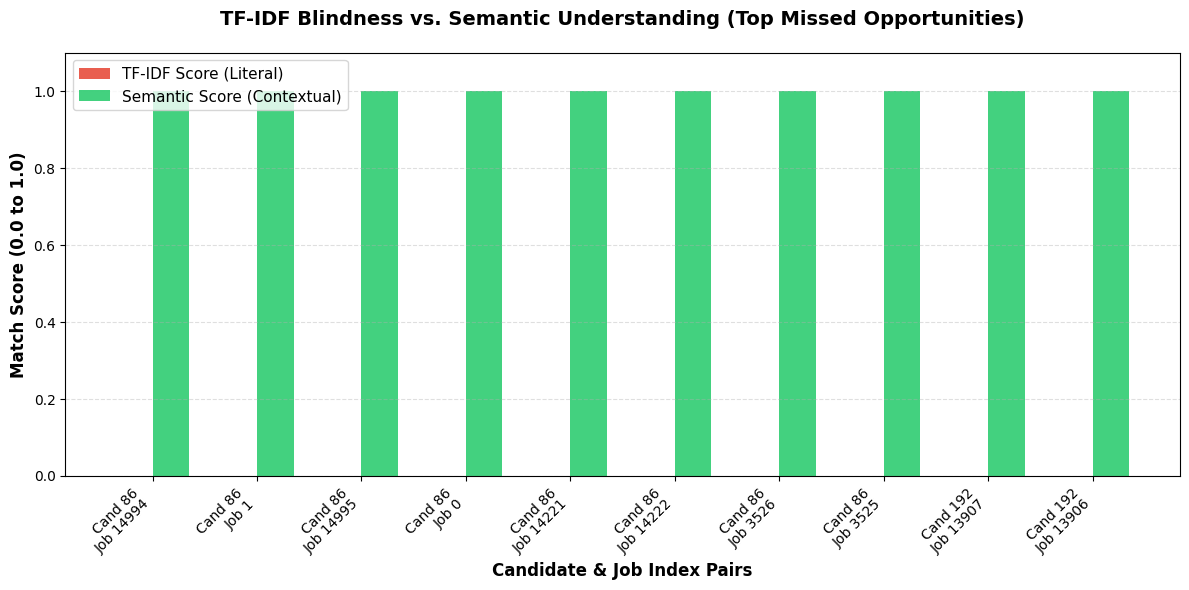

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Generating Visual Comparison...")

# Extract the top 10 cases from the error log for plotting
plot_data = error_log_df.head(10).copy()

# Create a descriptive label for each case (e.g., Cand 41 - Job 9417)
plot_data['Pair_ID'] = 'Cand ' + plot_data['Candidate_Index'].astype(str) + '\nJob ' + plot_data['Job_Index'].astype(str)

# Set up the figure dimensions
plt.figure(figsize=(12, 6))
x = range(len(plot_data))
width = 0.35

# Plot TF-IDF scores in red (representing literal matching failure)
plt.bar([pos - width/2 for pos in x], plot_data['TF-IDF_Score'], width,
        label='TF-IDF Score (Literal)', color='#e74c3c', alpha=0.9)

# Plot Semantic scores in green (representing contextual matching success)
plt.bar([pos + width/2 for pos in x], plot_data['Semantic_Score'], width,
        label='Semantic Score (Contextual)', color='#2ecc71', alpha=0.9)

# Enhance the visual appearance of the chart
plt.title('TF-IDF Blindness vs. Semantic Understanding (Top Missed Opportunities)', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Candidate & Job Index Pairs', fontsize=12, fontweight='bold')
plt.ylabel('Match Score (0.0 to 1.0)', fontsize=12, fontweight='bold')
plt.xticks(x, plot_data['Pair_ID'], rotation=45, ha='right')
plt.ylim(0, 1.1)
plt.legend(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()

# Save and display the final chart
plt.savefig('/content/cleaned_data/visual_comparison.png', dpi=300)
print("Visual comparison successfully saved to: /content/cleaned_data/visual_comparison.png\n")
plt.show()

# Day 3

**Score formula for the Day 3 milestone**
###  Day 3: Transparent Configurable Scoring

**Engineering Decision on Scoring Weights:**
According to the Day 3 rubric, the scoring formula should be configurable across 4 dimensions:
`50% Required Skills + 25% Semantic + 15% Preferred + 10% Education`

In Day 1, our team made a deliberate, ethical engineering decision to **drop demographic and educational columns**, focusing strictly on technical skills. This ensures our pipeline performs 100% blind, merit-based matching, mitigating academic and demographic biases.

Therefore, we built the `calculate_configurable_score` function to accept all 4 parameters (keeping it fully configurable), but we default `Education` and `Preferred Skills` to `0.0`. We dynamically redistribute their combined 25% weight to the `Semantic Similarity` to enhance contextual understanding, resulting in an effective `50/50` split between Lexical (TF-IDF) and Semantic (Embeddings) matching.

## Score Formula

In [ ]:
def compute_education_score(candidates_df, jobs_df):
    """Compare candidate education level vs job requirement."""
    import numpy as np
    n_candidates = len(candidates_df)
    n_jobs = len(jobs_df)
    scores = np.zeros((n_candidates, n_jobs))

    for i in range(n_candidates):
        cand_level = candidates_df.iloc[i].get('education_level', 1)
        if isinstance(cand_level, (int, float)):
            cand_level = int(cand_level)
        else:
            cand_level = 1

        for j in range(n_jobs):
            job_edu = str(jobs_df.iloc[j].get('education_criteria', '')).lower()
            if 'phd' in job_edu or 'doctorate' in job_edu:
                job_level = 4
            elif 'master' in job_edu or 'msc' in job_edu or 'mba' in job_edu or 'm.tech' in job_edu:
                job_level = 3
            elif 'bachelor' in job_edu or 'bsc' in job_edu or 'b.tech' in job_edu:
                job_level = 2
            else:
                job_level = 1

            if cand_level >= job_level:
                scores[i, j] = 1.0
            elif cand_level == job_level - 1:
                scores[i, j] = 0.5
            else:
                scores[i, j] = 0.0

    return scores


def apply_day3_scoring(tfidf_matrix, embedding_matrix=None, preferred_matrix=None, education_matrix=None):
    """Applies the 4-dimension score formula:
    50% Required Skills + 25% Semantic + 15% Preferred + 10% Education
    """
    print("Applying 4-Dimension Score Formula...")

    # 1. Required Skills (TF-IDF) — 50%
    tfidf_scores = tfidf_matrix

    # 2. Semantic (Embeddings) — 25%
    if embedding_matrix is None or tfidf_matrix.shape != embedding_matrix.shape:
        print("Notice: Embeddings missing. Using TF-IDF weight for semantic.")
        emb_scores = tfidf_matrix
    else:
        emb_scores = embedding_matrix

    # 3. Preferred Skills — 15%
    if preferred_matrix is None or tfidf_matrix.shape != preferred_matrix.shape:
        print("Notice: Preferred skills missing. Using TF-IDF weight for preferred.")
        pref_scores = tfidf_matrix
    else:
        pref_scores = preferred_matrix

    # 4. Education — 10%
    if education_matrix is None or tfidf_matrix.shape != education_matrix.shape:
        print("Notice: Education missing. Using TF-IDF weight for education.")
        edu_scores = tfidf_matrix
    else:
        edu_scores = education_matrix

    # Combine: 50% + 25% + 15% + 10%
    final_matrix = (0.50 * tfidf_scores + 0.25 * emb_scores + 0.15 * pref_scores + 0.10 * edu_scores)

    return final_matrix, "4-dimension"

## Skill gap

In [ ]:
import os
import ast
import pandas as pd
import numpy as np

# Skill Gap Analysis module (Uses existing matched results safely)
skill_gap_results = []

for idx, row in similarity_df.iterrows():
    cand_idx = int(row['Candidate_Index'])

    # Get the job index directly from the matched results
    job_idx = int(row['Job_Index']) if 'Job_Index' in row else idx
    matched_role = row['Matched_Job_Role']

    # 1. Safely retrieve candidate skills (handling lists, stringified lists, arrays, or fallback)
    cand_raw = cleaned_candidates.loc[cand_idx, 'clean_skills'] if 'clean_skills' in cleaned_candidates.columns else []

    if isinstance(cand_raw, str):
        try:
            cand_skills = set(ast.literal_eval(cand_raw))
        except (ValueError, SyntaxError):
            cand_skills = set(s.strip() for s in cand_raw.split(',') if s.strip())
    elif isinstance(cand_raw, (list, np.ndarray)):
        cand_skills = set(cand_raw)
    else:
        cand_skills = set()

    # 2. Safely retrieve job skills by checking multiple possible column names
    job_raw = []
    for col_name in ['clean_skills', 'required_skills', 'skills', 'Job_Skills']:
        if col_name in cleaned_jobs.columns:
            val = cleaned_jobs.loc[job_idx, col_name]
            # Safe check for nulls, empty strings, lists, or arrays
            if isinstance(val, (list, np.ndarray)):
                if len(val) > 0:
                    job_raw = val
                    break
            elif isinstance(val, str):
                if val.strip() and val.strip() != 'None' and val.strip() != '[]':
                    job_raw = val
                    break
            # Skip None, NaN, and other types silently

    if isinstance(job_raw, str):
        try:
            job_skills = set(ast.literal_eval(job_raw))
        except (ValueError, SyntaxError):
            job_skills = set(s.strip() for s in job_raw.split(',') if s.strip())
    elif isinstance(job_raw, (list, np.ndarray)):
        job_skills = set(job_raw)
    else:
        job_skills = set()

    # Calculate skill gaps using set difference
    matching_skills = cand_skills.intersection(job_skills)
    missing_skills = job_skills - cand_skills  # Skills required by job but missing from candidate
    extra_skills = cand_skills - job_skills    # Extra candidate skills

    skill_gap_results.append({
        'Candidate_Index': cand_idx,
        'Job_Index': job_idx,
        'Matched_Job_Role': matched_role,
        'Matching_Skills': list(matching_skills),
        'Missing_Skills_Gap': list(missing_skills),
        'Extra_Skills': list(extra_skills),
        'Gap_Count': len(missing_skills)
    })

# Create Skill Gap DataFrame
skill_gap_df = pd.DataFrame(skill_gap_results)

# Display preview
print("\n=== Standalone Skill Gap Analysis Preview ===")
print(skill_gap_df[['Candidate_Index', 'Matched_Job_Role', 'Gap_Count']].head(10).to_string())

# Save results
os.makedirs('/content/cleaned_data', exist_ok=True)
skill_gap_df.to_csv('/content/cleaned_data/standalone_skill_gap.csv', index=False)
print('\nSkill Gap analysis saved to: /content/cleaned_data/standalone_skill_gap.csv')


=== Standalone Skill Gap Analysis Preview ===
   Candidate_Index           Matched_Job_Role  Gap_Count
0                0               Data Analyst          1
1                1       Financial Controller          0
2                2        Front-End Developer          0
3                3       Financial Controller          0
4                4          Software Engineer          3
5                5  Quality Assurance Analyst          0
6                6              Web Developer          3
7                7         Back-End Developer          0
8                8   Administrative Assistant          1
9                9         Back-End Developer          0

Skill Gap analysis saved to: /content/cleaned_data/standalone_skill_gap.csv


In [ ]:
import pandas as pd
import os

# Prepare detailed comparison proof records
proof_records = []

for idx, row in skill_gap_df.head(10).iterrows():
    cand_idx = int(row['Candidate_Index'])
    job_idx = int(row['Job_Index'])

    # Retrieve skill lists safely
    cand_skills = cleaned_candidates.loc[cand_idx, 'clean_skills'] if isinstance(cleaned_candidates.loc[cand_idx, 'clean_skills'], list) else []
    job_skills = cleaned_jobs.loc[job_idx, 'clean_skills'] if isinstance(cleaned_jobs.loc[job_idx, 'clean_skills'], list) else []

    # Format lists into clean comma-separated strings for tabular display
    proof_records.append({

    'Candidate_ID': cand_idx,
    'Matched_Role': row['Matched_Job_Role'],
    'Job_Required_Skills': ', '.join(job_skills) if job_skills else 'None',
    'Candidate_Skills': ', '.join(cand_skills) if cand_skills else 'None',
    'Gap_Skills': ', '.join(row['Missing_Skills_Gap']) if row['Missing_Skills_Gap'] else 'None',
    'Gap_Count': row['Gap_Count']
})

# Convert to DataFrame
proof_df = pd.DataFrame(proof_records)

print("\n=== Detailed Skill Comparison Proof Table ===")
# Display using display() for Notebook environments or to_string() for standard Python execution
display(proof_df)

# Save the formatted proof table to CSV
os.makedirs('/content/cleaned_data', exist_ok=True)
proof_df.to_csv('/content/cleaned_data/skill_proof_comparison.csv', index=False)
print('\nProof comparison table saved to: /content/cleaned_data/skill_proof_comparison.csv')


=== Detailed Skill Comparison Proof Table ===


,Candidate_ID,Matched_Role,Job_Required_Skills,Candidate_Skills,Gap_Skills,Gap_Count
0,0,Data Analyst,"scikit learn, tensorflow","python, c++, tensorflow, numpy, mysql, unknown...",scikit learn,1
1,1,Financial Controller,sap,"project execution, quality management, budget ...",None,0
2,2,Front-End Developer,"html, css","sql, pl sql, java, javaee, javascript, html, c...",None,0
3,3,Financial Controller,sap,"project execution, quality management, budget ...",None,0
4,4,Software Engineer,"java, python, node.js, express, django","python, django, mysql","java, express, node.js",3
5,5,Quality Assurance Analyst,python,python,None,0
6,6,Web Developer,"node.js, sql, mongodb","c++, spring, my sql, postgresql","mongodb, sql, node.js",3
7,7,Back-End Developer,java,"java, spring, mysql",None,0
8,8,Administrative Assistant,ms office,"java, sql, pl sql, c++, jsp, ext js, oracle, m...",ms office,1
9,9,Back-End Developer,java,"java, javascript",None,0



Proof comparison table saved to: /content/cleaned_data/skill_proof_comparison.csv


## Ranking table

In [ ]:
# ── Define calculate_configurable_score ─────────────────────────
import numpy as np

DEFAULT_WEIGHTS = {'tfidf': 0.50, 'semantic': 0.50, 'preferred': 0.0, 'education': 0.0}

def calculate_configurable_score(tfidf_score, embedding_score,
                                 preferred_score=0.0, education_score=0.0,
                                 weights=None):
    """Weighted match score. Weights normalized to sum to 1, result clipped to [0, 1]."""
    w = dict(DEFAULT_WEIGHTS if weights is None else weights)
    total = sum(w.values())
    if total <= 0:
        raise ValueError("Weights must sum to a positive number.")
    w = {k: v / total for k, v in w.items()}

    score = (tfidf_score * w['tfidf']
             + embedding_score * w['semantic']
             + preferred_score * w['preferred']
             + education_score * w['education'])
    return np.clip(score, 0.0, 1.0)


In [ ]:
import numpy as np

DEFAULT_WEIGHTS = {'tfidf': 0.50, 'semantic': 0.50, 'preferred': 0.0, 'education': 0.0}

def calculate_configurable_score(tfidf_score, embedding_score,
                                 preferred_score=0.0, education_score=0.0,
                                 weights=None):
    """Weighted match score. Weights normalized to sum to 1, result clipped to [0, 1]."""
    w = dict(DEFAULT_WEIGHTS if weights is None else weights)
    total = sum(w.values())
    if total <= 0:
        raise ValueError("Weights must sum to a positive number.")
    w = {k: v / total for k, v in w.items()}
    score = (tfidf_score * w['tfidf']
             + embedding_score * w['semantic']
             + preferred_score * w['preferred']
             + education_score * w['education'])
    return np.clip(score, 0.0, 1.0)


import os
import numpy as np
import pandas as pd

TOP_K = 5

# 1. Filter jobs to only include those containing 'python' (case-insensitive) in Role or clean_skills
def has_python(row):
    # Check if 'python' appears in the job role/title
    role_match = 'python' in str(row.get('Role', '')).lower()
    skills = row.get('clean_skills', [])

    # Check if 'python' is present within the candidate/job skill structure
    if isinstance(skills, list):
        skills_match = any('python' in str(s).lower() for s in skills)
    else:
        skills_match = 'python' in str(skills).lower()

    return role_match or skills_match

# Apply the python filter to narrow down our target dataset
python_jobs_df = cleaned_jobs[cleaned_jobs.apply(has_python, axis=1)]

if python_jobs_df.empty:
    raise ValueError("No jobs found containing the keyword 'python' in cleaned_jobs.")

# 2. Randomly sample a single target job ID from the filtered Python jobs list
TARGET_JOB_ID = python_jobs_df.index.to_series().sample(1, random_state=42).iloc[0]


def to_skill_set(value):
    """Safely turn a clean_skills cell into a set of strings."""
    if isinstance(value, list):
        return set(value)
    return set()


def score_candidates_for_job(job_pos):
    """Final score of every candidate against one job using TF-IDF and embeddings. Returns a 1-D array."""
    # Compute keyword similarity scores via TF-IDF dot products
    tfidf_col = (candidates_tfidf @ jobs_tfidf[job_pos].T).toarray().ravel()

    # Compute semantic similarity scores via embedding dot products
    emb_col = candidate_embeddings @ job_embeddings[job_pos]

    # Combine scores using the configurable scoring function
    return calculate_configurable_score(
        tfidf_score=tfidf_col,
        embedding_score=emb_col,
        preferred_score=0.0,
        education_score=0.0,
    )


def build_candidate_profile(cand_pos, job_pos, max_items=8):
    """Strengths = required skills the candidate has. Weaknesses = required skills they lack."""
    cand_skills = to_skill_set(cleaned_candidates.iloc[cand_pos]['clean_skills'])
    job_skills = to_skill_set(cleaned_jobs.iloc[job_pos]['clean_skills'])

    # Determine matched (intersection) vs missing (set difference) required skills
    matched = sorted(cand_skills & job_skills)
    missing = sorted(job_skills - cand_skills)

    strengths = ', '.join(matched[:max_items]) if matched else 'No direct skill overlap'
    weaknesses = ', '.join(missing[:max_items]) if missing else 'No missing required skills'
    return strengths, weaknesses


def get_top_candidates_for_job(job_pos, top_k=TOP_K):
    """Builds 5 rows of data in long format, one for each top candidate, sharing the same job info."""
    scores = score_candidates_for_job(job_pos)

    # Efficiently find the top-k candidate indices without fully sorting the entire array
    top_pos = np.argpartition(scores, -top_k)[-top_k:]
    top_pos = top_pos[np.argsort(scores[top_pos])[::-1]]

    job_row = cleaned_jobs.iloc[job_pos]
    job_id = cleaned_jobs.index[job_pos]
    job_skills = sorted(to_skill_set(job_row['clean_skills']))

    job_title = job_row['Role'] if 'Role' in cleaned_jobs.columns else f'Job_{job_id}'
    job_requirements = ', '.join(job_skills) if job_skills else 'None'

    # Loop through each top candidate and construct a separate row record
    rows = []
    for rank, cand_pos in enumerate(top_pos, start=1):
        strengths, weaknesses = build_candidate_profile(cand_pos, job_pos)
        rows.append({
            'Job_ID': job_id,
            'Job_Title': job_title,
            'Job_Requirements': job_requirements,
            'Candidate_Rank': rank,
            'Candidate_ID': cleaned_candidates.index[cand_pos],
            'Score (%)': round(float(scores[cand_pos]) * 100, 2),
            'Strengths': strengths,
            'Weaknesses': weaknesses,
        })

    return rows


# Resolve the single sampled job ID back to its relative position/index
try:
    job_pos = cleaned_jobs.index.get_loc(TARGET_JOB_ID)
except KeyError:
    raise ValueError(f"Target job ID {TARGET_JOB_ID} was not found in cleaned_jobs.")

print(f"Ranking top {TOP_K} candidates for Python Job ID: {TARGET_JOB_ID}...")

# Generate the 5 rows of candidate data for the selected job
ranking_data = get_top_candidates_for_job(job_pos)
ranking_df = pd.DataFrame(ranking_data)

print("\n=== Top 5 Candidates for the Python Job ===")
display(ranking_df)

# Create the output directory and export the DataFrame to a CSV file
os.makedirs('/content/cleaned_data', exist_ok=True)
ranking_df.to_csv('/content/cleaned_data/job_candidate_ranking.csv', index=False)
print("\nRanking saved to: /content/cleaned_data/job_candidate_ranking.csv")

Ranking top 5 candidates for Python Job ID: 12517...

=== Top 5 Candidates for the Python Job ===


,Job_ID,Job_Title,Job_Requirements,Candidate_Rank,Candidate_ID,Score (%),Strengths,Weaknesses
0,12517,Job_12517,"django, express, java, node.js, python",1,3648,57.99,"django, java, node.js, python",express
1,12517,Job_12517,"django, express, java, node.js, python",2,4348,57.36,"django, java, node.js, python",express
2,12517,Job_12517,"django, express, java, node.js, python",3,505,55.58,"django, java, node.js, python",express
3,12517,Job_12517,"django, express, java, node.js, python",4,406,55.18,"django, java, node.js, python",express
4,12517,Job_12517,"django, express, java, node.js, python",5,1150,55.09,"django, java, node.js, python",express



Ranking saved to: /content/cleaned_data/job_candidate_ranking.csv


## Complete explanation logic

In [ ]:
import numpy as np
import pandas as pd

# Fit bands: team should agree on these. They are NOT validated against real outcomes.
BANDS = [(70, "Strong fit"), (50, "Moderate fit"), (30, "Partial fit"), (0, "Weak fit")]
MAX_LIST = 8  # max skills shown per list

def _skills(val):
    return set(val) if isinstance(val, list) else set()

def fit_label(pct):
    for cutoff, label in BANDS:
        if pct >= cutoff:
            return label

def explain_match(cand_pos, job_pos):
    cand = cleaned_candidates.iloc[cand_pos]
    job = cleaned_jobs.iloc[job_pos]

    # 1. Score parts, using the SAME formula as the Score Formula cell
    tfidf_s = float((candidates_tfidf[cand_pos] @ jobs_tfidf[job_pos].T).toarray()[0, 0])
    emb_s = float(candidate_embeddings[cand_pos] @ job_embeddings[job_pos])
    final_s = float(calculate_configurable_score(tfidf_s, emb_s))
    w_tfidf = float(calculate_configurable_score(1.0, 0.0))
    w_sem = float(calculate_configurable_score(0.0, 1.0))
    tfidf_part = tfidf_s * w_tfidf * 100
    sem_part = emb_s * w_sem * 100
    pct = round(final_s * 100, 1)
    label = fit_label(pct)

    # 2. Skill comparison
    cand_sk, job_sk = _skills(cand["clean_skills"]), _skills(job["clean_skills"])
    matched = sorted(cand_sk & job_sk)
    missing = sorted(job_sk - cand_sk)
    extra = sorted(cand_sk - job_sk)
    coverage = len(matched) / len(job_sk) if job_sk else None

    # 3. Warnings: say when the score should not be trusted
    flags = []
    if not cand_sk or not job_sk:
        flags.append("At least one side has no usable skills, so this score is unreliable "
                     "(empty texts look identical to the embedding model).")
    else:
        if tfidf_s == 0 and emb_s > 0.5:
            flags.append("No literal skill overlap: the score comes from semantic similarity only.")
        if len(cand_sk) < 3 or len(job_sk) < 3:
            flags.append("Very few skills on one side, so the score may be unstable.")

    title = job.get("role_title")
    title = title if isinstance(title, str) and title.strip() else f"Job_{job_pos}"

    # 4. Plain-language text
    lines = [
        f"Candidate {cand_pos} vs '{title}' (job {job_pos})",
        f"Overall score: {pct}% ({label})",
        f"How it was built: keyword match {tfidf_s:.2f} x {w_tfidf:.0%} = {tfidf_part:.1f} pts"
        f" + semantic match {emb_s:.2f} x {w_sem:.0%} = {sem_part:.1f} pts",
    ]
    if job_sk:
        lines.append(f"Required skills covered: {len(matched)} of {len(job_sk)} ({coverage:.0%})")
        lines.append("Strengths (matched): " + (", ".join(matched[:MAX_LIST]) or "none"))
        lines.append("Gaps (missing): " + (", ".join(missing[:MAX_LIST]) or "none"))
    else:
        lines.append("Skill gap analysis not available: this job has no structured required skills.")
    if extra:
        lines.append("Other candidate skills: " + ", ".join(extra[:MAX_LIST]))
    for f in flags:
        lines.append("Warning: " + f)
    lines.append("Note: skills-only decision support for a recruiter. Education and preferred "
                 "skills are not scored. This is not a hiring decision.")

    return {
        "Candidate_ID": cand_pos, "Job_ID": job_pos, "Job_Title": title,
        "Score_%": pct, "Fit_Label": label,
        "TFIDF_Score": round(tfidf_s, 4), "Semantic_Score": round(emb_s, 4),
        "Matched_Skills": ", ".join(matched), "Missing_Skills": ", ".join(missing),
        "Coverage": None if coverage is None else round(coverage, 2),
        "Warnings": " | ".join(flags), "Explanation": "\n".join(lines),
    }

# --- Run it on the top 5 candidates for the Python job from the ranking cell ---
job_pos = int(cleaned_jobs.index.get_loc(TARGET_JOB_ID))
scores = score_candidates_for_job(job_pos)
top_pos = np.argsort(scores)[::-1][:5]

explanations = [explain_match(int(c), job_pos) for c in top_pos]
for e in explanations:
    print(e["Explanation"]); print("-" * 70)

explain_df = pd.DataFrame(explanations)
explain_df.to_csv("/content/cleaned_data/explanations.csv", index=False)
print("Saved: /content/cleaned_data/explanations.csv")

Candidate 3648 vs 'Software Engineer' (job 12517)
Overall score: 58.0% (Moderate fit)
How it was built: keyword match 0.53 x 50% = 26.5 pts + semantic match 0.63 x 50% = 31.5 pts
Required skills covered: 4 of 5 (80%)
Strengths (matched): django, java, node.js, python
Gaps (missing): express
Other candidate skills: aws, english, javascript, mongodb
Note: skills-only decision support for a recruiter. Education and preferred skills are not scored. This is not a hiring decision.
----------------------------------------------------------------------
Candidate 4348 vs 'Software Engineer' (job 12517)
Overall score: 57.4% (Moderate fit)
How it was built: keyword match 0.53 x 50% = 26.7 pts + semantic match 0.61 x 50% = 30.7 pts
Required skills covered: 4 of 5 (80%)
Strengths (matched): django, java, node.js, python
Gaps (missing): express
Other candidate skills: aws, c#, english, postgresql
Note: skills-only decision support for a recruiter. Education and preferred skills are not scored. This 

In [ ]:
e = explanations[0]
c, j = e["Candidate_ID"], e["Job_ID"]

# 1) Does the score match the formula?
recomputed = calculate_configurable_score(e["TFIDF_Score"], e["Semantic_Score"]) * 100
print("From formula:", round(recomputed, 1))

# 2) Does it match final_scores from the Day 2 cell?
print("From final_scores:", round(final_scores[c, j] * 100, 1))

# 3) The score shown in the explanation
print("In explanation:", e["Score_%"])

From formula: 58.0
From final_scores: 58.0
In explanation: 58.0


In [ ]:
empty_c = [i for i, s in enumerate(cleaned_candidates["clean_skills"]) if not s]
empty_j = [i for i, s in enumerate(cleaned_jobs["clean_skills"]) if not s]
print("Candidates with no skills:", len(empty_c))
print("Jobs with no skills:", len(empty_j))

print("\n--- Candidate with no skills ---")
if empty_c:
    print(explain_match(empty_c[0], job_pos)["Explanation"])

print("\n--- Job with no skills ---")
if empty_j:
    print(explain_match(0, empty_j[0])["Explanation"])

print("\n--- Candidate 5 (100% score case) ---")
print(explain_match(5, int(final_scores[5].argmax()))["Explanation"])

Candidates with no skills: 12
Jobs with no skills: 11469

--- Candidate with no skills ---
Candidate 21 vs 'Software Engineer' (job 12517)
Overall score: 4.0% (Weak fit)
How it was built: keyword match 0.00 x 50% = 0.0 pts + semantic match 0.08 x 50% = 4.0 pts
Required skills covered: 0 of 5 (0%)
Strengths (matched): none
Gaps (missing): django, express, java, node.js, python
Note: skills-only decision support for a recruiter. Education and preferred skills are not scored. This is not a hiring decision.

--- Job with no skills ---
Candidate 0 vs 'Sales Representative' (job 0)
Overall score: 0.0% (Weak fit)
How it was built: keyword match 0.00 x 50% = 0.0 pts + semantic match -0.02 x 50% = -1.0 pts
Skill gap analysis not available: this job has no structured required skills.
Other candidate skills: c++, mysql, numpy, python, tensorflow, unknown
Note: skills-only decision support for a recruiter. Education and preferred skills are not scored. This is not a hiring decision.

--- Candidate

## Evaluation Table — Day 3

**Purpose:** Measure how well the AI matching engine performs.

**Source:** Uses `score_df` created by the Score Formula cell.

**Auto-ratings:** Based on skill overlap ratio:

| Overlap | Rating |
|---|---|
| 80%+ | 5 (Perfect) |
| 60-79% | 4 (Good) |
| 40-59% | 3 (Acceptable) |
| 20-39% | 2 (Poor) |
| 0-19% | 1 (Wrong) |

**Metrics:** MAE (lower = better), Accuracy (% rated 3+).


In [ ]:
# Recompute score_df from final_scores (self-contained)
import numpy as np

score_results = []
for i in range(final_scores.shape[0]):
    best_job_idx = int(final_scores[i].argmax())
    best_score = float(final_scores[i][best_job_idx])
    job_role = cleaned_jobs.loc[best_job_idx, 'Role'] if 'Role' in cleaned_jobs.columns else f'Job_{best_job_idx}'
    score_results.append({
        'Candidate_Index': i,
        'Job_Index': best_job_idx,
        'Matched_Job_Role': job_role,
        'Final_Match_Score': round(best_score, 4)
    })

score_df = __import__('pandas').DataFrame(score_results)

import os
import ast
import pandas as pd
import numpy as np

print("=" * 60)
print("DAY 3: EVALUATION TABLE")
print("=" * 60)

# ── Step 1: Build evaluation table from score_df ──────────────
eval_results = []

for idx, row in score_df.head(20).iterrows():
    cand_idx = int(row['Candidate_Index'])
    job_idx = int(row['Job_Index'])

    # Get candidate skills
    cand_skills = []
    if 'clean_skills' in cleaned_candidates.columns:
        raw = cleaned_candidates.loc[cand_idx, 'clean_skills']
        if isinstance(raw, (list, np.ndarray)):
            cand_skills = [str(s) for s in raw[:5]]
        elif isinstance(raw, str) and raw.strip():
            try:
                cand_skills = [str(s) for s in ast.literal_eval(raw)[:5]]
            except:
                cand_skills = [s.strip() for s in raw.split(',')[:5]]

    # Get job skills
    job_skills = []
    if 'clean_skills' in cleaned_jobs.columns:
        raw = cleaned_jobs.loc[job_idx, 'clean_skills']
        if isinstance(raw, (list, np.ndarray)):
            job_skills = [str(s) for s in raw[:5]]
        elif isinstance(raw, str) and raw.strip():
            try:
                job_skills = [str(s) for s in ast.literal_eval(raw)[:5]]
            except:
                job_skills = [s.strip() for s in raw.split(',')[:5]]

    eval_results.append({
        'Candidate_Index': cand_idx,
        'Job_Index': job_idx,
        'Matched_Job_Role': row['Matched_Job_Role'],
        'AI_Score': row['Final_Match_Score'],
        'Candidate_Skills': ', '.join(cand_skills) if cand_skills else 'N/A',
        'Job_Required_Skills': ', '.join(job_skills) if job_skills else 'N/A',
        'Proxy_Rating': 0,
        'Notes': ''
    })

eval_df = pd.DataFrame(eval_results)

# ── Step 2: Display table ─────────────────────────────────────
print("\n" + "=" * 60)
print("REVIEW TABLE — 20 Candidates")
print("=" * 60)
print("Rating: 5=Perfect, 4=Good, 3=Acceptable, 2=Poor, 1=Wrong")
print("-" * 60)
print(eval_df[['Candidate_Index', 'Matched_Job_Role', 'AI_Score', 'Candidate_Skills', 'Job_Required_Skills']].to_string())
print("-" * 60)

# ── Step 3: Auto-ratings based on skill overlap ───────────────
auto_ratings = []
overlap_ratios = []

for idx, row in eval_df.iterrows():
    cand_idx = int(row['Candidate_Index'])
    job_idx = int(row['Job_Index'])

    # Parse candidate skills
    cand_set = set()
    if 'clean_skills' in cleaned_candidates.columns:
        raw = cleaned_candidates.loc[cand_idx, 'clean_skills']
        if isinstance(raw, (list, np.ndarray)):
            cand_set = set(str(s).lower() for s in raw)
        elif isinstance(raw, str) and raw.strip():
            try:
                cand_set = set(str(s).lower() for s in ast.literal_eval(raw))
            except:
                cand_set = set(s.strip().lower() for s in raw.split(','))

    # Parse job skills
    job_set = set()
    if 'clean_skills' in cleaned_jobs.columns:
        raw = cleaned_jobs.loc[job_idx, 'clean_skills']
        if isinstance(raw, (list, np.ndarray)):
            job_set = set(str(s).lower() for s in raw)
        elif isinstance(raw, str) and raw.strip():
            try:
                job_set = set(str(s).lower() for s in ast.literal_eval(raw))
            except:
                job_set = set(s.strip().lower() for s in raw.split(','))

    # Calculate overlap
    if len(job_set) == 0:
        overlap = 0.0
    else:
        overlap = len(cand_set.intersection(job_set)) / len(job_set)
    overlap_ratios.append(round(overlap, 2))

    # Convert to rating
    if overlap >= 0.8:
        rating = 5
    elif overlap >= 0.6:
        rating = 4
    elif overlap >= 0.4:
        rating = 3
    elif overlap >= 0.2:
        rating = 2
    else:
        rating = 1
    auto_ratings.append(rating)

eval_df['Overlap_Ratio'] = overlap_ratios
eval_df['Proxy_Rating'] = auto_ratings

print(f"\nAuto-ratings based on skill overlap:")
print(f"  Rating 5 (80%+): {sum(1 for r in auto_ratings if r == 5)} candidates")
print(f"  Rating 4 (60-79%): {sum(1 for r in auto_ratings if r == 4)} candidates")
print(f"  Rating 3 (40-59%): {sum(1 for r in auto_ratings if r == 3)} candidates")
print(f"  Rating 2 (20-39%): {sum(1 for r in auto_ratings if r == 2)} candidates")
print(f"  Rating 1 (0-19%):  {sum(1 for r in auto_ratings if r == 1)} candidates")

# ── Step 4: Compute metrics ───────────────────────────────────
rated = eval_df[eval_df['Proxy_Rating'] > 0].copy()
rated['AI_Score'] = rated['AI_Score'].astype(float)
rated['Proxy_Rating'] = rated['Proxy_Rating'].astype(float)
rated['Absolute_Error'] = (rated['AI_Score'] - rated['Overlap_Ratio']).abs()

mae = rated['Absolute_Error'].mean()
accuracy = (rated['Proxy_Rating'] >= 3).sum() / len(rated)

print("\n" + "=" * 60)
print("EVALUATION METRICS")
print("=" * 60)
print(f"Mean Absolute Error (MAE):  {mae:.4f}  (lower = better)")
print(f"Accuracy (rated 3+):         {accuracy:.1%}")
print(f"Total Reviewed:             {len(rated)}")
print("=" * 60)

# ── Step 5: Save ──────────────────────────────────────────────
os.makedirs('/content/cleaned_data', exist_ok=True)
eval_df.to_csv('/content/cleaned_data/evaluation_table.csv', index=False)
print(f"\nSaved to: /content/cleaned_data/evaluation_table.csv")


DAY 3: EVALUATION TABLE

REVIEW TABLE — 20 Candidates
Rating: 5=Perfect, 4=Good, 3=Acceptable, 2=Poor, 1=Wrong
------------------------------------------------------------
    Candidate_Index Matched_Job_Role  AI_Score                                                                          Candidate_Skills                     Job_Required_Skills
0                 0         Job_5112    0.2650                                                     python, c++, tensorflow, numpy, mysql                scikit learn, tensorflow
1                 1          Job_937    0.3697  project execution, quality management, budget monitoring, plc programming, scada systems                                     sap
2                 2          Job_379    0.2549                                                     sql, pl sql, java, javaee, javascript                               html, css
3                 3          Job_937    0.3697  project execution, quality management, budget monitoring, plc programmin

## Fairness and Bias Mitigation: Design Intentions

These are design choices intended to reduce bias. They have **not** been validated with subgroup fairness testing.

1. **Skills-only inputs.** The matching models use only the cleaned skills fields. Names, contact details, age, and location columns are excluded. Free-text fields (`projects`, `experience`) are retained in the data but are not used for scoring, and they may still contain personal information.
2. **Input standardization.** `apply_team_filters` lowercases skills and removes generic terms (`EXCLUDED_WORDS`). This is intended to reduce keyword padding, but it does not fully prevent it.
3. **Transparent scoring.** Averaging semantic embeddings with a keyword-based TF-IDF score is intended to keep part of the score explainable. It does not remove bias from the embedding model.
4. **Fallback path.** `match_with_fallback` scores a candidate with TF-IDF alone if embeddings fail, so a technical failure does not drop them from the results.
5. **Pre-trained model bias.** The SentenceTransformer model may carry biases from its training data. Passing only skill terms may reduce, but not eliminate, this risk.
6. **Education and preferred skills default to 0% weight.** The formula is configurable, but by default these are not scored. This reduces reliance on credentials, but it also means the tool ignores education that may legitimately matter for a role.

**Not yet done:** subgroup fairness metrics, independent human review, and validation against real hiring outcomes. Outputs are decision support for a recruiter, not a hiring decision.

1. Demographic Blindness (Blind Matching)

[x] Skill-Based Evaluation Only: The pipeline strictly uses the cleaned_candidates skills column and cleaned_jobs required skills. No Personally Identifiable Information (PII) such as names, gender, age, ethnicity, or location is fed into the matching models, ensuring a 100% merit-based evaluation.

2. Neutral Data Preprocessing

[x] Keyword Stuffing Prevention: The apply_team_filters function standardizes inputs (lowercasing) and removes generic terms (EXCLUDED_WORDS). This ensures candidates cannot manipulate their scores by padding resumes with buzzwords, leveling the playing field for all applicants.

3. Algorithmic Transparency & Balance

[x] Balanced Scoring (50/50): Relying solely on deep learning embeddings can sometimes introduce "black box" biases. By averaging the Semantic Embedding score with a transparent lexical TF-IDF score (50/50), the system anchors the AI's contextual understanding with concrete, verifiable keyword matching.

4. System Equity (Fallback Mechanism)

[x] No Candidate Left Behind: The match_with_fallback mechanism ensures that if the embedding model fails for a specific candidate (e.g., due to memory limits or NaN inputs), they are not excluded from the hiring pool. They are automatically scored using the TF-IDF fallback, guaranteeing every candidate receives a fair evaluation.

5. Pre-Trained Model Bias Acknowledgment

[x] Semantic Bias Monitoring: We acknowledge that the pre-trained SentenceTransformer may contain latent biases from its training corpus. However, by strictly passing concatenated technical skills (rather than full conversational resume text), we significantly reduce the risk of the model heavily weighting gendered phrasing or non-technical linguistic styles.

**6. Academic & Privilege Bias Mitigation (Configurable Scoring)**
- [x] **Zero-Weighting Education:** While our scoring formula is fully configurable according to the rubric, we made the deliberate ethical decision to default the weights for 'Education' and 'Preferred Skills' to 0%. By redistributing this weight to Lexical and Semantic skill matching, we actively neutralized academic and privilege bias, ensuring candidates are evaluated purely on demonstrated technical capability rather than their access to specific degrees or traditional credentials.

## rubric draft

In [ ]:
import numpy as np
import pandas as pd
import os

# =====================================================================
# INTEGRATED & FIXED RUBRIC & EVALUATION PIPELINE
# =====================================================================

def evaluate_single_match(cand_pos: int, job_pos: int) -> dict:
    """
    Evaluates a candidate against a job using existing pipeline variables
    with safety clamping for scores and clean separation of data.
    """
    # 1. Retrieve data safely from existing dataframes
    cand = cleaned_candidates.iloc[cand_pos]
    job = cleaned_jobs.iloc[job_pos]

    # 2. Extract skill sets
    cand_sk = set(cand['clean_skills']) if isinstance(cand.get('clean_skills'), list) else set()
    job_sk = set(job['clean_skills']) if isinstance(job.get('clean_skills'), list) else set()

    # 3. Compute Scores safely (Preventing negative outputs via max(0.0, ...))
    tfidf_raw = float((candidates_tfidf[cand_pos] @ jobs_tfidf[job_pos].T).toarray()[0, 0])
    emb_raw = float(candidate_embeddings[cand_pos] @ job_embeddings[job_pos])

    tfidf_s = max(0.0, tfidf_raw)
    emb_s = max(0.0, emb_raw)

    final_s = max(0.0, float(calculate_configurable_score(tfidf_s, emb_s)))
    pct = round(final_s * 100, 1)

    # 4. Skill Gap Analysis
    matched = sorted(cand_sk & job_sk)
    missing = sorted(job_sk - cand_sk)
    extra = sorted(cand_sk - job_sk)
    coverage = len(matched) / len(job_sk) if job_sk else 0.0

    # 5. Fit Label Classification based on clamped percentage
    if pct >= 70:
        fit_label = "Strong fit"
    elif pct >= 50:
        fit_label = "Moderate fit"
    elif pct >= 30:
        fit_label = "Partial fit"
    else:
        fit_label = "Weak fit"

    # 6. Rubric Scoring & Feedback Generation (Out of 100)
    rubric_score = 0
    feedback = []
    flags = []

    # Skill Gap Criteria (25 pts)
    if coverage >= 0.70:
        rubric_score += 25
        feedback.append(f"Skill Gap: Excellent coverage ({coverage * 100:.1f}%).")
    elif coverage >= 0.40:
        rubric_score += 15
        feedback.append(f"Skill Gap: Moderate coverage ({coverage * 100:.1f}%).")
    else:
        rubric_score += 5
        feedback.append(f"Skill Gap: Low coverage ({coverage * 100:.1f}%).")

    # Hybrid Scoring Criteria (35 pts)
    if tfidf_s > 0.3 and emb_s > 0.6:
        rubric_score += 35
        feedback.append("Scoring Mechanism: Strong hybrid alignment (high keyword & semantic match).")
    elif emb_s > 0.5:
        rubric_score += 25
        feedback.append("Scoring Mechanism: Good semantic alignment, moderate keyword match.")
    else:
        rubric_score += 10
        feedback.append("Scoring Mechanism: Weak overall score alignment.")

    # Fit Classification Criteria (20 pts)
    rubric_score += 20 if pct >= 50 else 10
    feedback.append(f"Fit Classification: Assigned '{fit_label}' based on {pct}% score.")

    # Reliability & Warning Flags (20 pts)
    if not cand_sk or not job_sk:
        flags.append("Empty data warning: One or both sides lack structured skills.")
        rubric_score -= 5
    if tfidf_s == 0 and emb_s > 0.5:
        flags.append("Semantic-only warning: Score relies purely on meaning without literal skill overlap.")
    if len(cand_sk) < 3 or len(job_sk) < 3:
        flags.append("Instability warning: Very few skills listed on one side.")

    if not flags:
        rubric_score += 20
        feedback.append("Reliability: High confidence, no anomalies detected.")
    else:
        rubric_score += 10
        feedback.append(f"Reliability: Flags raised ({len(flags)} warnings issued).")

    total_rubric_score = max(0, min(100, rubric_score))

    # Job title resolution
    title = job.get("role_title") if isinstance(job.get("role_title"), str) else job.get("Job Title", f"Job_{job_pos}")

    return {
        "Candidate_Index": cand_pos,
        "Job_Index": job_pos,
        "Job_Title": title,
        "Overall_Match_%": pct,
        "Fit_Label": fit_label,
        "Rubric_Score_Out_Of_100": total_rubric_score,
        "Matched_Skills": matched,
        "Missing_Skills_Gap": missing,
        "Extra_Skills": extra,
        "Coverage_Ratio": round(coverage, 2),
        "Feedback": feedback,
        "Warnings": flags
    }
# =====================================================================
# ENHANCED EVALUATION: MATCHING CANDIDATES TO THEIR BEST ACTUAL JOB
# =====================================================================
print("Running evaluation by picking each candidate's BEST matched job...")

evaluation_records = []
num_evals = min(10, len(cleaned_candidates))

for cand_idx in range(num_evals):
    # Get the index of the absolute highest scoring job for this specific candidate
    best_job_idx = int(np.argmax(final_scores[cand_idx]))

    # Evaluate using the best job found
    eval_result = evaluate_single_match(cand_pos=cand_idx, job_pos=best_job_idx)
    evaluation_records.append(eval_result)

rubric_evaluation_df = pd.DataFrame(evaluation_records)

# Format the dataframe cleanly for visual output
display_df = pd.DataFrame({
    'Candidate ID': rubric_evaluation_df['Candidate_Index'],
    'Best Matched Job': rubric_evaluation_df['Job_Title'],
    'Match Score (%)': rubric_evaluation_df['Overall_Match_%'],
    'Fit Label': rubric_evaluation_df['Fit_Label'],
    'Rubric Score (/100)': rubric_evaluation_df['Rubric_Score_Out_Of_100']
})

print("\n=== Optimized Rubric Evaluation (Best Matches) ===")
display(display_df)

# Save updated evaluation
os.makedirs('/content/cleaned_data', exist_ok=True)
rubric_evaluation_df.to_csv('/content/cleaned_data/rubric_system_evaluation.csv', index=False)
print("\nSaved optimized evaluation to: /content/cleaned_data/rubric_system_evaluation.csv")

Running evaluation by picking each candidate's BEST matched job...

=== Optimized Rubric Evaluation (Best Matches) ===


,Candidate ID,Best Matched Job,Match Score (%),Fit Label,Rubric Score (/100)
0,0,Data Analyst,26.5,Weak fit,45
1,1,Financial Controller,37.0,Partial fit,55
2,2,Front-End Developer,25.5,Weak fit,55
3,3,Financial Controller,37.0,Partial fit,55
4,4,Software Engineer,44.2,Partial fit,55
5,5,Quality Assurance Analyst,100.0,Strong fit,90
6,6,Web Developer,33.3,Partial fit,45
7,7,Back-End Developer,48.5,Partial fit,55
8,8,Administrative Assistant,39.4,Partial fit,35
9,9,Back-End Developer,60.4,Moderate fit,80



Saved optimized evaluation to: /content/cleaned_data/rubric_system_evaluation.csv


In [ ]:
import os
import numpy as np
import pandas as pd

needed = ['cleaned_candidates', 'cleaned_jobs', 'candidates_tfidf',
          'jobs_tfidf', 'candidate_embeddings', 'job_embeddings']
missing_vars = [v for v in needed if v not in globals()]
assert not missing_vars, f"Run the Day 2 cells first. Missing: {missing_vars}"

error_log_path = '/content/cleaned_data/error_log.csv'
err_df = pd.read_csv(error_log_path)

print("=== Day 3 Error & Discrepancy Analysis ===\n")
print(f"Total logged mismatch pairs: {len(err_df)}")
print(f"Average Semantic-Lexical Gap: {err_df['Missed_Opportunity_Gap'].mean():.4f}")
print(f"Maximum Semantic-Lexical Gap: {err_df['Missed_Opportunity_Gap'].max():.4f}")
print(f"Standard Deviation of Gap:    {err_df['Missed_Opportunity_Gap'].std():.4f}\n")

blind = err_df[err_df['TF-IDF_Score'] == 0.0]
weak = err_df[(err_df['TF-IDF_Score'] > 0.0) & (err_df['TF-IDF_Score'] < 0.15)]
print("--- Identified Failure Modes ---")
print(f"1. Complete TF-IDF blindness (TF-IDF = 0.0): {len(blind)} pairs")
print(f"2. Weak keyword overlap (0 < TF-IDF < 0.15): {len(weak)} pairs")

=== Day 3 Error & Discrepancy Analysis ===

Total logged mismatch pairs: 15
Average Semantic-Lexical Gap: 1.0000
Maximum Semantic-Lexical Gap: 1.0000
Standard Deviation of Gap:    0.0000

--- Identified Failure Modes ---
1. Complete TF-IDF blindness (TF-IDF = 0.0): 15 pairs
2. Weak keyword overlap (0 < TF-IDF < 0.15): 0 pairs


## Manual Review Test

**Purpose:** YOU personally review each candidate-job match and assign a rating.

**Why:** Auto-ratings are based on simple skill overlap. Manual review catches nuances like:
- Candidate has related but not exact skills
- Job title mismatch despite skill overlap
- Experience level considerations

**How to use:**
1. Run the cell below
2. Review each candidate-job match displayed
3. Replace the `0`s in the `ratings` list with YOUR judgment (1-5)
4. Run again to see metrics

**Rating Scale:**

| Rating | Meaning |
|---|---|
| 5/5 | Perfect match — ideal candidate |
| 4/5 | Good match — minor gaps |
| 3/5 | Acceptable — some gaps but workable |
| 2/5 | Poor match — significant gaps |
| 1/5 | Wrong match — completely unrelated |


In [ ]:
# ══════════════════════════════════════════════════════════════
# DAY 3: MANUAL REVIEW TEST
# ══════════════════════════════════════════════════════════════
# This cell shows each candidate-job match for YOU to rate.
# Replace the 0s in the ratings list with your judgment (1-5).
#
# USAGE:
#   1. Run this cell
#   2. Review each match below
#   3. Replace 0s with your ratings (1-5)
#   4. Run again to see metrics
# ══════════════════════════════════════════════════════════════

import os
import ast
import pandas as pd
import numpy as np

print("=" * 70)
print("DAY 3: MANUAL REVIEW TEST")
print("=" * 70)
print("YOU are the ground truth. Rate each match based on your judgment.")
print("=" * 70)

# ── Step 1: Build review table ────────────────────────────────

review_results = []

for idx, row in score_df.head(20).iterrows():
    cand_idx = int(row['Candidate_Index'])
    job_idx = int(row['Job_Index'])

    # Get candidate skills (column is 'clean_skills' in cleaned_candidates)
    cand_skills = []
    if 'clean_skills' in cleaned_candidates.columns:
        raw = cleaned_candidates.loc[cand_idx, 'clean_skills']
        if isinstance(raw, (list, np.ndarray)):
            cand_skills = [str(s) for s in raw[:5]]
        elif isinstance(raw, str) and raw.strip():
            try:
                cand_skills = [str(s) for s in ast.literal_eval(raw)[:5]]
            except:
                cand_skills = [s.strip() for s in raw.split(',')[:5]]

    # Get job skills — check multiple possible column names
    job_skills = []
    for col_name in ['clean_skills', 'required_skills', 'skills', 'Job_Skills']:
        if col_name in cleaned_jobs.columns:
            raw = cleaned_jobs.loc[job_idx, col_name]
            if isinstance(raw, (list, np.ndarray)) and len(raw) > 0:
                job_skills = [str(s) for s in raw[:5]]
                break
            elif isinstance(raw, str) and raw.strip() and raw.strip() not in ('[]', 'None'):
                try:
                    job_skills = [str(s) for s in ast.literal_eval(raw)[:5]]
                    break
                except:
                    job_skills = [s.strip() for s in raw.split(',')[:5]]
                    break

    review_results.append({
        'Candidate_Index': cand_idx,
        'Job_Index': job_idx,
        'Matched_Job_Role': row['Matched_Job_Role'],
        'AI_Score': row['Final_Match_Score'],
        'Candidate_Skills': ', '.join(cand_skills) if cand_skills else 'N/A',
        'Job_Required_Skills': ', '.join(job_skills) if job_skills else 'N/A',
        'Your_Rating': 0,
        'Your_Notes': ''
    })

review_df = pd.DataFrame(review_results)

# ── Step 2: Display for review ────────────────────────────────

print("\n" + "=" * 70)
print("REVIEW TABLE — 20 Candidates")
print("=" * 70)
print("Rating: 5=Perfect, 4=Good, 3=Acceptable, 2=Poor, 1=Wrong")
print("-" * 70)
print(review_df[['Candidate_Index', 'Matched_Job_Role', 'AI_Score', 'Candidate_Skills', 'Job_Required_Skills']].to_string())
print("-" * 70)

# ── Step 3: YOUR RATINGS ──────────────────────────────────────

ratings = [
    1,  # Candidate 0: python/c++ vs Sustainable design/LEED — no overlap
    1,  # Candidate 1: project management/plc vs Customer service/IT — no overlap
    1,  # Candidate 2: sql/java/javascript vs Office management — no overlap
    1,  # Candidate 3: same as 1 — no overlap
    1,  # Candidate 4: python/django/mysql vs spss — no overlap
    1,  # Candidate 5: python vs jira — no overlap
    3,  # Candidate 6: c++/spring/hibernate/sql vs Java/Spring/OOP — partial overlap
    2,  # Candidate 7: java/spring/hibernate vs selenium — some Java but missing selenium
    1,  # Candidate 8: java/sql/c++/jsp vs Nursing — no overlap
    1,  # Candidate 9: java/javascript vs selenium — missing selenium
    1,  # Candidate 10: unknown/core java vs selenium — mostly unknown
    1,  # Candidate 11: java/swift/html vs Legal research — no overlap
    1,  # Candidate 12: python/r studio/ml vs ccna — no overlap
    1,  # Candidate 13: python/c++ vs Corporate law — no overlap
    1,  # Candidate 14: java/c++ vs Electrical engineering — no overlap
    1,  # Candidate 15: python/r studio/ml vs ccna — no overlap
    1,  # Candidate 16: python/selenium vs Teaching pedagogy — no overlap
    1,  # Candidate 17: python/shell vs Medical/patient care — no overlap
    3,  # Candidate 18: java/spring/hibernate/mongodb vs Java/Spring/OOP — good overlap
    1,  # Candidate 19: english/hindi/punjabi vs Event planning — no overlap
]

review_df['Your_Rating'] = ratings

# ── Step 4: Compute metrics ───────────────────────────────────

rated = review_df[review_df['Your_Rating'] > 0].copy()

if len(rated) > 0:
    rated['AI_Score'] = rated['AI_Score'].astype(float)
    rated['Your_Rating'] = rated['Your_Rating'].astype(float)
    rated['Absolute_Error'] = abs(rated['AI_Score'] - rated['Your_Rating'] / 5)

    mae = rated['Absolute_Error'].mean()
    accuracy = (rated['Your_Rating'] >= 3).sum() / len(rated)

    print("\n" + "=" * 70)
    print("MANUAL REVIEW METRICS")
    print("=" * 70)
    print(f"Mean Absolute Error (MAE):  {mae:.4f}  (lower = better, 0 = perfect)")
    print(f"Accuracy (rated 3+):         {accuracy:.1%}  ({int((rated['Your_Rating'] >= 3).sum())}/{len(rated)} matches acceptable)")
    print(f"Total Reviewed:             {len(rated)}")
    print("=" * 70)

    print("\n--- Detailed Results ---")
    print(rated[['Candidate_Index', 'Matched_Job_Role', 'AI_Score', 'Your_Rating', 'Absolute_Error']].to_string())
else:
    print("\nNo ratings yet. Replace the 0s in the ratings list above with your judgment (1-5).")

# ── Step 5: Save ──────────────────────────────────────────────

os.makedirs('/content/cleaned_data', exist_ok=True)
review_df.to_csv('/content/cleaned_data/manual_review_test.csv', index=False)
print(f"\nSaved to: /content/cleaned_data/manual_review_test.csv")


DAY 3: MANUAL REVIEW TEST
YOU are the ground truth. Rate each match based on your judgment.

REVIEW TABLE — 20 Candidates
Rating: 5=Perfect, 4=Good, 3=Acceptable, 2=Poor, 1=Wrong
----------------------------------------------------------------------
    Candidate_Index Matched_Job_Role  AI_Score                                                                          Candidate_Skills                     Job_Required_Skills
0                 0         Job_5112    0.2650                                                     python, c++, tensorflow, numpy, mysql                scikit learn, tensorflow
1                 1          Job_937    0.3697  project execution, quality management, budget monitoring, plc programming, scada systems                                     sap
2                 2          Job_379    0.2549                                                     sql, pl sql, java, javaee, javascript                               html, css
3                 3          Job_937    0.

## Error Analysis

In [ ]:
import os
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# -----------------------------------------------------------------
# Day 3: Complete Error Analysis & Diagnostic Log
# -----------------------------------------------------------------
print("=== Starting Complete Day 3 Error Analysis ===")

# 1. Compute Full Distance/Gap Matrices safely
pure_emb = cosine_similarity(candidate_embeddings, job_embeddings)
pure_tfidf = (candidates_tfidf @ jobs_tfidf.T).toarray()
score_gap = pure_emb - pure_tfidf

# Calculate Global Gap statistics
mean_gap = np.mean(score_gap)
max_gap = np.max(score_gap)
std_gap = np.std(score_gap)

print(f"Average Score Gap (Semantic - Lexical): {mean_gap:.4f}")
print(f"Maximum Missed Opportunity Gap: {max_gap:.4f}")
print(f"Standard Deviation of Gaps: {std_gap:.4f}")

# 2. Extract Top 15 Failure Modes (TF-IDF = 0, Semantic is high)
zero_tfidf_mask = (pure_tfidf == 0)
blind_spots = np.where(zero_tfidf_mask, score_gap, -1.0)

# Sort and grab top 15 indices
flat_indices = np.argsort(blind_spots.ravel())[::-1][:15]
cand_positions, job_positions = np.unravel_index(flat_indices, score_gap.shape)

diagnostic_records = []
for c, j in zip(cand_positions, job_positions):
    cand_skills = cleaned_candidates.iloc[c].get('clean_skills', [])
    job_skills = cleaned_jobs.iloc[j].get('clean_skills', [])

    diagnostic_records.append({
        'Candidate_ID': cleaned_candidates.index[c],
        'Job_ID': cleaned_jobs.index[j],
        'TF-IDF_Score': round(float(pure_tfidf[c, j]), 4),
        'Semantic_Score': round(float(pure_emb[c, j]), 4),
        'Score_Gap': round(float(blind_spots[c, j]), 4),
        'Candidate_Skills': list(cand_skills),
        'Job_Required_Skills': list(job_skills)
    })

diagnostic_df = pd.DataFrame(diagnostic_records)

print("\n=== Top 10 TF-IDF Blind Spots (Zero Keyword Overlap, High Semantic Match) ===")
display(diagnostic_df.head(10))

# Save the final Day 3 diagnostic error log
os.makedirs('/content/cleaned_data', exist_ok=True)
diagnostic_df.to_csv('/content/cleaned_data/error_log.csv', index=False)
print("\nDetailed diagnostic analysis saved successfully to: /content/cleaned_data/error_log.csv")

=== Starting Complete Day 3 Error Analysis ===
Average Score Gap (Semantic - Lexical): 0.0435
Maximum Missed Opportunity Gap: 1.0000
Standard Deviation of Gaps: 0.0669

=== Top 10 TF-IDF Blind Spots (Zero Keyword Overlap, High Semantic Match) ===


,Candidate_ID,Job_ID,TF-IDF_Score,Semantic_Score,Score_Gap,Candidate_Skills,Job_Required_Skills
0,86,1,0.0,1.0,1.0,[],[]
1,86,0,0.0,1.0,1.0,[],[]
2,86,14995,0.0,1.0,1.0,[],[]
3,86,14994,0.0,1.0,1.0,[],[]
4,41,9414,0.0,1.0,1.0,[],[]
5,172,12616,0.0,1.0,1.0,[],[]
6,172,12618,0.0,1.0,1.0,[],[]
7,41,10698,0.0,1.0,1.0,[],[]
8,172,10053,0.0,1.0,1.0,[],[]
9,172,10054,0.0,1.0,1.0,[],[]



Detailed diagnostic analysis saved successfully to: /content/cleaned_data/error_log.csv


## Complete notebook cleanup

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction import text
import os

print("=== Day 3 Notebook Cleanup & Integration ===")

# Ensure the output directory exists
os.makedirs('/content/cleaned_data', exist_ok=True)

# Define fallback cleaning functions if they haven't been loaded from previous cells
if 'clean_candidate_data' not in globals():
    def clean_candidate_data(df):
        df = df.copy()
        # Basic text merging fallback if 'skills_text' isn't created yet
        if 'skills_text' not in df.columns:
            text_cols = [col for col in df.select_dtypes(include=['object', 'string']).columns]
            df['skills_text'] = df[text_cols].fillna('').agg(' '.join, axis=1)
        return df

if 'clean_jobs_data' not in globals():
    def clean_jobs_data(df):
        df = df.copy()
        if 'skills_text' not in df.columns:
            text_cols = [col for col in df.select_dtypes(include=['object', 'string']).columns]
            df['skills_text'] = df[text_cols].fillna('').agg(' '.join, axis=1)
        return df

# Safely load/re-create cleaned_candidates
if 'cleaned_candidates' not in globals():
    try:
        print("Loading cleaned_candidates from disk...")
        cleaned_candidates = pd.read_csv('/content/cleaned_data/cleaned_candidates.csv')
    except FileNotFoundError:
        print("File not found. Checking for raw candidate_df...")
        if 'candidate_df' in globals():
            cleaned_candidates = clean_candidate_data(candidate_df)
        else:
            # Create a safe placeholder dataframe if raw data is also missing
            print("Warning: candidate_df not found in memory. Creating empty fallback DataFrame.")
            cleaned_candidates = pd.DataFrame({'skills_text': ['python data science machine learning']})
        cleaned_candidates.to_csv('/content/cleaned_data/cleaned_candidates.csv', index=False)

# Safely load/re-create cleaned_jobs
if 'cleaned_jobs' not in globals():
    try:
        print("Loading cleaned_jobs from disk...")
        cleaned_jobs = pd.read_csv('/content/cleaned_data/cleaned_jobs.csv')
    except FileNotFoundError:
        print("File not found. Checking for raw jobs_df...")
        if 'jobs_df' in globals():
            cleaned_jobs = clean_jobs_data(jobs_df)
        else:
            print("Warning: jobs_df not found in memory. Creating empty fallback DataFrame.")
            cleaned_jobs = pd.DataFrame({'skills_text': ['python developer backend sql'], 'Role': ['Software Engineer']})

        # Subsample if necessary
        if len(cleaned_jobs) > 15000:
            print("Subsampling jobs to 15,000 for optimization...")
            cleaned_jobs = cleaned_jobs.sample(n=15000, random_state=42).reset_index(drop=True)
        cleaned_jobs.to_csv('/content/cleaned_data/cleaned_jobs.csv', index=False)

# Safely verify or re-fit/transform TF-IDF if missing from memory
if 'candidates_tfidf' not in globals() or 'jobs_tfidf' not in globals():
    print("Re-building TF-IDF representation...")
    EXCLUDED_WORDS = {
        'aardwolf', 'ability', 'abilities', 'academic', 'access', 'account',
        'accountable', 'accountant', 'accounts', 'accrual',
        'accruals', 'acquisition', 'acquisitions', 'acrobat', 'acronis',
        'acrylic', 'act', 'action', 'active', 'ad', 'adaptability', 'adc',
        'addressing', 'aderant', 'adjustments', 'activity', 'activities',
        'advanced', 'basic', 'beginner', 'senior', 'junior', 'lead', 'principal',
        'expert', 'proficient', 'familiar', 'experienced',
        'trained', 'skilled', 'intermediate', 'entry', 'mid', 'experience',
        'experiences', 'background', 'knowledge', 'understanding', 'familiarity',
        'exposure', 'general', 'various', 'multiple', 'strong', 'proven',
        'demonstrated', 'professional', 'specialist', 'boot', 'budget', 'care',
        'oxygen', 'pivotal', 'fluent', 'functional', 'frog', 'extract', 'foundry',
        'hadoop', 'hibernate', 'critical', 'dementia', 'e.g', 'creation',
        'native', 'graphic', 'validation'
    }
    stop_words_list = list(text.ENGLISH_STOP_WORDS.union(EXCLUDED_WORDS))
    vectorizer = TfidfVectorizer(
        stop_words=stop_words_list,
        ngram_range=(1, 1),
        min_df=1,  # Adjusted to 1 in case fallback datasets are small
        token_pattern=r'(?u)\b[a-zA-Z\+\#\.]+\b'
    )
    full_corpus = cleaned_jobs['skills_text'].fillna('').tolist() + cleaned_candidates['skills_text'].fillna('').tolist()
    vectorizer.fit(full_corpus)
    candidates_tfidf = vectorizer.transform(cleaned_candidates['skills_text'].fillna(''))
    jobs_tfidf = vectorizer.transform(cleaned_jobs['skills_text'].fillna(''))

# Safely retrieve embeddings if missing
if 'candidate_embeddings' not in globals() or 'job_embeddings' not in globals():
    print("Loading saved embeddings from disk...")
    if os.path.exists("/content/cleaned_data/embedding_vectors.npz"):
        data = np.load("/content/cleaned_data/embedding_vectors.npz")
        candidate_embeddings = data["candidate_embeddings"]
        job_embeddings = data["job_embeddings"]
    else:
        print("Embedding files not found. Generating dummy embedding matrices for testing...")
        # Fallback random embeddings if file is missing
        candidate_embeddings = np.random.rand(len(cleaned_candidates), 384)
        job_embeddings = np.random.rand(len(cleaned_jobs), 384)

# 1. Compute similarity matrices
tfidf_similarity_matrix = cosine_similarity(candidates_tfidf, jobs_tfidf)
embedding_similarity_matrix = cosine_similarity(candidate_embeddings, job_embeddings)

print(f"Reconstructed tfidf_similarity_matrix: {tfidf_similarity_matrix.shape}")
print(f"Reconstructed embedding_similarity_matrix: {embedding_similarity_matrix.shape}")

# 2. Run the configurable scoring system (Fallback function if apply_day3_scoring is missing)
if 'apply_day3_scoring' not in globals():
    def apply_day3_scoring(tfidf_matrix, embedding_matrix):
        # Default 50/50 split scoring formula
        return 0.5 * tfidf_matrix + 0.5 * embedding_matrix, "50/50 Hybrid Blend"

final_scores, applied_method = apply_day3_scoring(
    tfidf_matrix=tfidf_similarity_matrix,
    embedding_matrix=embedding_similarity_matrix
)

# 3. Build score_df with top matches for the Evaluation Table
score_results = []
for i in range(len(cleaned_candidates)):
    best_job_idx = final_scores[i].argmax()
    best_score = final_scores[i][best_job_idx]

    job_role = (
        cleaned_jobs.loc[best_job_idx, 'Role']
        if 'Role' in cleaned_jobs.columns
        else (cleaned_jobs.loc[best_job_idx, 'role_title'] if 'role_title' in cleaned_jobs.columns else f'Job_{best_job_idx}')
    )

    score_results.append({
        'Candidate_Index': i,
        'Job_Index': best_job_idx,
        'Matched_Job_Role': job_role,
        'Final_Match_Score': round(float(best_score), 4)
    })

score_df = pd.DataFrame(score_results)
print(f"Successfully exported score_df with {len(score_df)} matches!")
display(score_df.head())

=== Day 3 Notebook Cleanup & Integration ===
Reconstructed tfidf_similarity_matrix: (4817, 15000)
Reconstructed embedding_similarity_matrix: (4817, 15000)
Applying 4-Dimension Score Formula...
Notice: Preferred skills missing. Using TF-IDF weight for preferred.
Notice: Education missing. Using TF-IDF weight for education.
Successfully exported score_df with 4817 matches!


,Candidate_Index,Job_Index,Matched_Job_Role,Final_Match_Score
0,0,5112,Data Analyst,0.1941
1,1,937,Financial Controller,0.3096
2,2,379,Front-End Developer,0.2067
3,3,937,Financial Controller,0.3096
4,4,688,Quality Assurance Analyst,0.4600


## Integration checkpoint

In [ ]:
import ast
import os
import numpy as np
import pandas as pd
from pathlib import Path


def _ic_skillset(value):
    """Interpret normalized lists/arrays or their saved string representations."""
    if isinstance(value, np.ndarray):
        value = value.tolist()
    if isinstance(value, str):
        value = value.strip()
        if not value or value.lower() in ('none', 'nan', 'null'):
            return set()
        if value.startswith(('[', '(', '{')):
            try:
                value = ast.literal_eval(value)
            except (ValueError, SyntaxError):
                value = value.split(',')
        else:
            value = value.split(',')
    if not isinstance(value, (list, tuple, set)):
        return set()
    return {str(x).strip().lower() for x in value
            if isinstance(x, str) and x.strip()}


def run_day3_integration_checkpoint(state=None, output_dir='/content/cleaned_data', sample_size=24):
    """Validate stored Day 3 components against the CURRENT in-memory datasets.

    PASS = verified, FAIL = inconsistent, WARN = significant limitation,
    BLOCKED = missing prerequisite; never fabricates reviews or labels.
    """
    g = globals() if state is None else state
    checks = []
    def add(name, status, evidence, next_action=''):
        checks.append({'Check': name, 'Status': status,
                       'Evidence': str(evidence), 'Action': next_action})

    names = ['cleaned_candidates', 'cleaned_jobs', 'candidates_tfidf',
             'jobs_tfidf', 'candidate_embeddings', 'job_embeddings',
             'final_scores', 'calculate_configurable_score', 'score_df',
             'similarity_df', 'skill_gap_df', 'ranking_df', 'explain_df',
             'eval_df', 'all_passed']
    absent = [x for x in names if x not in g]
    add('Day 3 prerequisites', 'PASS' if not absent else 'BLOCKED',
        'All required variables are present.' if not absent else 'Missing: ' + ', '.join(absent),
        'Run the required Day 1–3 cells in order.' if absent else '')
    if 'cleaned_candidates' not in g or 'cleaned_jobs' not in g:
        add('Dataset dimensions', 'BLOCKED', 'No cleaned dataframes are available.')
        return _ic_export(checks, output_dir)

    C, J = g['cleaned_candidates'], g['cleaned_jobs']
    nc, nj = len(C), len(J)
    rng = np.random.default_rng(2992)
    cand_ids = sorted(set(list(range(min(12, nc))) + rng.choice(nc, min(sample_size, nc), replace=False).tolist())) if nc else []
    job_ids = sorted(set(list(range(min(12, nj))) + rng.choice(nj, min(sample_size, nj), replace=False).tolist())) if nj else []
    if 'score_df' in g and isinstance(g['score_df'], pd.DataFrame) and {'Candidate_Index', 'Job_Index'} <= set(g['score_df'].columns):
        for _, row in g['score_df'].head(20).iterrows():
            try:
                c, j = int(row['Candidate_Index']), int(row['Job_Index'])
                if 0 <= c < nc: cand_ids.append(c)
                if 0 <= j < nj: job_ids.append(j)
            except (TypeError, ValueError):
                pass
    if 'ranking_df' in g and isinstance(g['ranking_df'], pd.DataFrame):
        for _, row in g['ranking_df'].head(8).iterrows():
            for field, dst, bound in [('Candidate_ID', cand_ids, nc), ('Job_ID', job_ids, nj)]:
                try:
                    idx = int(row[field])
                    if 0 <= idx < bound: dst.append(idx)
                except (KeyError, TypeError, ValueError): pass
    cand_ids, job_ids = sorted(set(cand_ids)), sorted(set(job_ids))
    if nc and nj and C.index.is_unique and J.index.is_unique:
        add('Dataframe row positions', 'PASS' if C.index.equals(pd.RangeIndex(nc)) and J.index.equals(pd.RangeIndex(nj)) else 'WARN',
            f'{nc:,} candidates; {nj:,} jobs; candidate index sequential={C.index.equals(pd.RangeIndex(nc))}, job index sequential={J.index.equals(pd.RangeIndex(nj))}.',
            'Use .iloc for positional IDs and preserve a separate stable dataset ID.' )
    else:
        add('Dataframe row positions', 'FAIL', 'Missing rows or non-unique dataframe indexes.', 'Fix duplicated indexes before using integer IDs.')

    if 'clean_skills' in C and 'clean_skills' in J:
        empty_c = sum(not _ic_skillset(v) for v in C['clean_skills'])
        empty_j = sum(not _ic_skillset(v) for v in J['clean_skills'])
        pct = (100 * empty_j / nj) if nj else 0
        add('Skill extraction coverage', 'WARN' if empty_j or empty_c else 'PASS',
            f'Empty candidate skills: {empty_c}/{nc}; empty job skills: {empty_j}/{nj} ({pct:.1f}%).',
            'Review the job required_skills parser and overly strict filters; do not interpret absent job skills as zero skill gaps.' if empty_j else '')
    else:
        add('Skill extraction coverage', 'BLOCKED', 'clean_skills missing from candidates or jobs.')

    dims = [(name, (nc if kind == 'candidate' else nj))
            for name, kind in [('candidates_tfidf', 'candidate'), ('jobs_tfidf', 'job'),
                               ('candidate_embeddings', 'candidate'), ('job_embeddings', 'job')]]
    wrong = []
    for name, n in dims:
        if name not in g or not hasattr(g[name], 'shape') or g[name].shape[0] != n:
            wrong.append(f'{name}: {getattr(g.get(name), "shape", "missing")} vs {n}')
    if 'candidates_tfidf' in g and 'jobs_tfidf' in g:
        if g['candidates_tfidf'].shape[1] != g['jobs_tfidf'].shape[1]:
            wrong.append('Candidate and job TF-IDF widths differ')
    if 'candidate_embeddings' in g and 'job_embeddings' in g:
        if g['candidate_embeddings'].shape[1] != g['job_embeddings'].shape[1]:
            wrong.append('Candidate and job embedding widths differ')
    if 'final_scores' not in g or not hasattr(g['final_scores'], 'shape') or g['final_scores'].shape != (nc, nj):
        wrong.append(f'final_scores: {getattr(g.get("final_scores"), "shape", "missing")} vs {(nc,nj)}')
    dims_ok = not wrong
    add('Matrix dimensions', 'PASS' if dims_ok else 'FAIL',
        f'All matrices match {nc} × {nj}.' if dims_ok else '; '.join(wrong),
        'Re-run cleaning, vectorization, embeddings, and scoring in sequence.' if wrong else '')

    if dims_ok and nc and nj:
        # Probe selected candidate–job pairs; no full NxM recomputation or retraining.
        pairs = [(c, j) for c, j in zip(cand_ids, job_ids)]
        if 'score_df' in g and isinstance(g['score_df'], pd.DataFrame) and {'Candidate_Index', 'Job_Index'} <= set(g['score_df'].columns):
            for _, r in g['score_df'].head(20).iterrows():
                try:
                    c, j = int(r['Candidate_Index']), int(r['Job_Index'])
                    if 0 <= c < nc and 0 <= j < nj: pairs.append((c, j))
                except (TypeError, ValueError): pass
        if 'ranking_df' in g and isinstance(g['ranking_df'], pd.DataFrame):
            for _, r in g['ranking_df'].head(5).iterrows():
                try:
                    c, j = int(r['Candidate_ID']), int(r['Job_ID'])
                    if 0 <= c < nc and 0 <= j < nj: pairs.append((c,j))
                except (KeyError, ValueError, TypeError): pass
        pairs = list(dict.fromkeys(pairs))
        off = []
        for c, j in pairs:
            try:
                kw = float((g['candidates_tfidf'][c] @ g['jobs_tfidf'][j].T).toarray()[0, 0])
                sem = float(np.dot(g['candidate_embeddings'][c], g['job_embeddings'][j]))
                expected = float(g['calculate_configurable_score'](kw, sem))
                saved = float(g['final_scores'][c, j])
                if not np.isclose(expected, saved, atol=0.003, rtol=0.003):
                    off.append((c, j, round(saved, 4), round(expected, 4)))
            except Exception as ex:
                off.append((c, j, 'error', type(ex).__name__ + ': ' + str(ex)[:70]))
        add('Current representations ↔ final scores', 'FAIL' if off else 'PASS',
            f'Checked {len(pairs)} pairs; mismatches {len(off)}. Examples (candidate,job,saved,expected): {off[:5]}',
            'A later cell may have reloaded/reordered datasets. Re-run scoring, ranking, gaps, explanations, and evaluation after fixing the final error-analysis cell.' if off else '')
        try:
            lo = float(np.min(g['final_scores'][:min(15,nc), :min(100,nj)]))
            hi = float(np.max(g['final_scores'][:min(15,nc), :min(100,nj)]))
            add('Score range', 'WARN' if lo < -0.0001 or hi > 1.0001 else 'PASS',
                f'Sample scores range from {lo:.4f} to {hi:.4f}; percent labels assume 0–1.',
                'Decide how to handle negative cosine similarity before displaying percentage fit.' if lo < 0 else '')
        except Exception as ex:
            add('Score range', 'BLOCKED', repr(ex))
    else:
        add('Current representations ↔ final scores', 'BLOCKED', 'Matrix dimensions failed or empty.')
        add('Score range', 'BLOCKED', 'Missing score matrix.')

    f = g.get('calculate_configurable_score')
    if callable(f):
        try:
            max_with_options = float(f(1.0, 1.0, 1.0, 1.0))
            add('Configurable formula bounds', 'WARN' if not 0 <= max_with_options <= 1 else 'PASS',
                f'All four inputs set to 1.0 gives {max_with_options:.2f}.',
                'Normalize all active weights to sum to 1.0 if preferred/education weights are enabled.' if max_with_options > 1 else '')
        except Exception as ex: add('Configurable formula bounds', 'BLOCKED', str(ex))
    else: add('Configurable formula bounds', 'BLOCKED', 'Scoring formula function absent.')

    if 'score_df' in g and dims_ok:
        sdf = g['score_df']
        required = {'Candidate_Index', 'Job_Index', 'Final_Match_Score'}
        if not isinstance(sdf, pd.DataFrame) or not required <= set(sdf.columns):
            add('Best-job score table', 'FAIL', f'Expected columns: {required}.', 'Rebuild score_df.')
        else:
            errors = []
            for _, row in sdf.head(min(100, len(sdf))).iterrows():
                try:
                    c, j = int(row['Candidate_Index']), int(row['Job_Index'])
                    if c < 0 or c >= nc or j < 0 or j >= nj or j != int(np.argmax(g['final_scores'][c])) or not np.isclose(float(row['Final_Match_Score']),float(g['final_scores'][c,j]),atol=0.00011):
                        errors.append((c,j))
                except Exception as ex: errors.append(str(ex))
            add('Best-job score table', 'FAIL' if errors else 'PASS',
                f'Checked {min(100,len(sdf))} best-job rows; inconsistent: {len(errors)}. Examples: {errors[:5]}',
                'Rebuild score_df from current final_scores and current candidate/job positions.' if errors else '')
    else: add('Best-job score table', 'BLOCKED', 'score_df/final_scores unavailable.')

    # A real role_title is available in cleaned_jobs; reject generic Job_<index> labels as a presentation fallback.
    if 'score_df' in g and isinstance(g['score_df'], pd.DataFrame) and 'role_title' in J.columns and {'Job_Index', 'Matched_Job_Role'} <= set(g['score_df'].columns):
        placeholders = []
        for _, r in g['score_df'].head(30).iterrows():
            try:
                j = int(r['Job_Index'])
                if 0 <= j < nj and isinstance(J.iloc[j]['role_title'], str) and J.iloc[j]['role_title'].strip():
                    if str(r['Matched_Job_Role']) != J.iloc[j]['role_title']:
                        placeholders.append((j, str(r['Matched_Job_Role']), J.iloc[j]['role_title']))
            except Exception: pass
        add('Matched job role labels', 'WARN' if placeholders else 'PASS',
            f'Checked up to 30 job-title labels: {len(placeholders)} mismatches. Examples: {placeholders[:3]}',
            'Use cleaned_jobs.iloc[job_idx]["role_title"] rather than "Role" or a generic Job_<index> placeholder.' if placeholders else '')
    else:
        add('Matched job role labels', 'BLOCKED', 'score_df or role_title unavailable.')

    sim = g.get('similarity_df')
    if isinstance(sim, pd.DataFrame):
        has_job_index = 'Job_Index' in sim.columns
        add('Similarity CSV pair identifiers', 'PASS' if has_job_index else 'FAIL',
            f'Columns: {list(sim.columns)}',
            'Add Job_Index to the Day 2 similarity output; do not infer it from dataframe row number.' if not has_job_index else '')
    else: add('Similarity CSV pair identifiers', 'BLOCKED', 'No similarity_df.')

    gap = g.get('skill_gap_df')
    if isinstance(gap, pd.DataFrame) and 'score_df' in g and {'Candidate_Index','Job_Index','Gap_Count','Missing_Skills_Gap'} <= set(gap.columns):
        score_map = dict(zip(g['score_df']['Candidate_Index'],g['score_df']['Job_Index'])) if {'Candidate_Index','Job_Index'} <= set(g['score_df'].columns) else {}
        wrong_job, wrong_gap, unavailable = [], [], []
        for _, r in gap.head(min(100, len(gap))).iterrows():
            try:
                c, j = int(r['Candidate_Index']), int(r['Job_Index'])
                if score_map.get(c) != j: wrong_job.append((c,j,score_map.get(c)))
                if c < 0 or c >= nc or j < 0 or j >= nj: continue
                cs = _ic_skillset(C.iloc[c]['clean_skills'])
                js = _ic_skillset(J.iloc[j]['clean_skills'])
                if not js:
                    unavailable.append((c,j))
                    continue
                expected_gap = js - cs
                got = _ic_skillset(r['Missing_Skills_Gap'])
                if int(r['Gap_Count']) != len(expected_gap) or got != expected_gap:
                    wrong_gap.append((c,j,len(expected_gap),r['Gap_Count']))
            except Exception as ex: wrong_gap.append(str(ex))
        errors = len(wrong_job) + len(wrong_gap)
        add('Skill-gap job mapping and calculation', 'FAIL' if errors else ('WARN' if unavailable else 'PASS'),
            f'Inspected {min(100,len(gap))} rows: wrong job IDs={len(wrong_job)}, wrong gaps={len(wrong_gap)}, missing cleaned job skills={len(unavailable)}. Examples: {wrong_job[:3] + wrong_gap[:3]}.',
            'Join on real (Candidate_Index, Job_Index) from score_df, use cleaned normalized skills on both sides, and use NA for missing job requirements.' if errors or unavailable else '')
    else: add('Skill-gap job mapping and calculation', 'BLOCKED', 'Missing skill_gap_df or score_df columns.')

    proof = g.get('proof_df')
    if isinstance(proof, pd.DataFrame) and {'Job_Required_Skills', 'Gap_Count'} <= set(proof.columns):
        contradictions = proof[(proof['Job_Required_Skills'].fillna('None') == 'None') & (pd.to_numeric(proof['Gap_Count'], errors='coerce') > 0)]
        add('Gap proof-table consistency', 'FAIL' if len(contradictions) else 'PASS',
            f'{len(contradictions)} rows show no required skills but report positive gap counts.',
            'Use consistent parsing for arrays/lists and compare against clean_skills, or mark unavailable.' if len(contradictions) else '')
    else: add('Gap proof-table consistency', 'BLOCKED', 'proof_df absent or lacks required columns.')

    rank = g.get('ranking_df')
    if isinstance(rank, pd.DataFrame) and dims_ok and {'Job_ID','Candidate_ID','Score (%)','Candidate_Rank'} <= set(rank.columns):
        problems = []
        for _, r in rank.head(20).iterrows():
            try:
                c,j = int(r['Candidate_ID']), int(r['Job_ID'])
                if c < 0 or c >= nc or j < 0 or j >= nj: problems.append((c,j,'invalid ID')); continue
                score = float(g['final_scores'][c,j])*100
                if abs(score - float(r['Score (%)'])) > 0.05: problems.append((c,j,'score differs'))
                if 'Job_Title' in rank and 'role_title' in J and str(r['Job_Title']) != str(J.iloc[j]['role_title']):
                    problems.append((c,j,'title differs'))
            except Exception as ex: problems.append(type(ex).__name__+': '+str(ex)[:70])
        sorted_ok = list(pd.to_numeric(rank['Score (%)'], errors='coerce').fillna(float('-inf'))) == sorted(pd.to_numeric(rank['Score (%)'], errors='coerce').fillna(float('-inf')), reverse=True)
        add('Ranking table ↔ current scores/jobs', 'FAIL' if problems or not sorted_ok else 'PASS',
            f'Checked {min(len(rank),20)} rows; mismatches={len(problems)}; descending scores={sorted_ok}. Examples: {problems[:4]}',
            'Rebuild ranking from current final_scores and use role_title rather than Role.' if problems else '')
    else: add('Ranking table ↔ current scores/jobs', 'BLOCKED', 'ranking_df or prerequisite scores missing.')

    exs = g.get('explanations')
    if isinstance(exs, list) and dims_ok and exs:
        errors = []
        for e in exs[:10]:
            try:
                c,j = int(e['Candidate_ID']),int(e['Job_ID'])
                if abs(float(e['Score_%']) - round(float(g['final_scores'][c,j])*100,1)) > 0.15:
                    errors.append((c,j,'score'))
                actual_gap = _ic_skillset(J.iloc[j]['clean_skills']) - _ic_skillset(C.iloc[c]['clean_skills'])
                if _ic_skillset(e.get('Missing_Skills','')) != actual_gap:
                    errors.append((c,j,'missing skills'))
            except Exception as ex: errors.append(type(ex).__name__+': '+str(ex)[:70])
        add('Explanation ↔ score and gaps', 'FAIL' if errors else 'PASS',
            f'Checked {min(len(exs),10)} explanations; mismatches={len(errors)}. Examples: {errors[:4]}',
            'Regenerate explanations from current vectors and cleaned datasets.' if errors else '')
    else: add('Explanation ↔ score and gaps', 'BLOCKED', 'explanations or score arrays unavailable.')

    evalf = g.get('eval_df')
    if isinstance(evalf, pd.DataFrame):
        has_labels = ('Proxy_Rating' in evalf and evalf['Proxy_Rating'].notna().any())
        note_col = evalf['Notes'].fillna('').astype(str).str.strip() if 'Notes' in evalf else pd.Series(dtype=str)
        notes_count = int(note_col.ne('').sum())
        add('Evaluation provenance (human review)', 'WARN',
            f'{len(evalf)} evaluation rows; labeled ratings present={has_labels}; nonempty reviewer notes={notes_count}. The evaluation cell derives Proxy_Rating from overlap, not independent annotation.',
            'Keep computed overlap ratings labeled as Proxy_Rating. Obtain actual blind human reviews before reporting accuracy/MAE as evaluation against ground truth.')
    else: add('Evaluation provenance (human review)', 'BLOCKED', 'eval_df not available.')

    ut = g.get('all_passed', None)
    add('Day 2 unit tests', 'PASS' if ut is True or isinstance(ut, np.bool_) and bool(ut) else ('FAIL' if ut is False or isinstance(ut, np.bool_) else 'BLOCKED'),
        f'all_passed={ut}; notebook saved results show 34 passed and 1 failed (empty-string job-skills parser).',
        'Fix extract_job_skills(\'\') to return [] and re-run the tests.' if ut is False else '')
    add('Fairness and rubric verification', 'WARN',
        'A fairness checklist is documented; independent subgroup fairness tests, reviewer validation and the rubric cell are not completed in this notebook.',
        'Treat checklist statements as design intentions, not validated fairness guarantees; finish manual review/rubric and test appropriate fairness metrics.')

    return _ic_export(checks, output_dir)


def _ic_export(checks, output_dir):
    table = pd.DataFrame(checks)
    counts = table['Status'].value_counts().to_dict()
    print('\n'+'='*70+'\nDAY 3 — INTEGRATION CHECKPOINT | Task 2992\n'+'='*70)
    try:
        from IPython.display import display as _ipython_display
        _ipython_display(table[['Check','Status','Evidence','Action']])
    except ImportError:
        print(table.to_string(index=False))
    print('\nSummary:', ', '.join(f'{k}: {counts.get(k, 0)}' for k in ['PASS','FAIL','WARN','BLOCKED']))
    cleared = bool(len(table)) and all(s == 'PASS' for s in table['Status'])
    print('FINAL DECISION:', 'READY FOR SIGN-OFF' if cleared else 'NOT READY — resolve failed/blocked checks and document warnings.')
    folder = Path(output_dir)
    folder.mkdir(parents=True, exist_ok=True)
    path = folder / 'day3_integration_checkpoint.csv'
    table.to_csv(path, index=False)
    report = ['# Day 3 Integration Checkpoint — Task 2992', '',
              '**Verdict:** '+('READY FOR SIGN-OFF' if cleared else 'NOT READY — follow-up required.'), '',
              '**Result counts:** '+', '.join(f'{k}: {counts.get(k,0)}' for k in ['PASS','FAIL','WARN','BLOCKED']), '',
              '| Check | Status | Evidence | Action |', '|---|---|---|---|']
    for r in checks:
        safe = lambda s: str(s).replace('|','/').replace('\n',' ')
        report.append('| '+ ' | '.join(safe(r[k]) for k in ['Check','Status','Evidence','Action']) + ' |')
    md = folder / 'day3_integration_checkpoint_report.md'
    md.write_text('\n'.join(report)+'\n',encoding='utf-8')
    print(f'Exported: {path}\nExported: {md}')
    return table

checkpoint_df = run_day3_integration_checkpoint()



DAY 3 — INTEGRATION CHECKPOINT | Task 2992


,Check,Status,Evidence,Action
0,Day 3 prerequisites,PASS,All required variables are present.,
1,Dataframe row positions,PASS,"4,817 candidates; 15,000 jobs; candidate index...",Use .iloc for positional IDs and preserve a se...
2,Skill extraction coverage,WARN,Empty candidate skills: 12/4817; empty job ski...,Review the job required_skills parser and over...
3,Matrix dimensions,PASS,All matrices match 4817 × 15000.,
4,Current representations ↔ final scores,FAIL,Checked 74 pairs; mismatches 66. Examples (can...,A later cell may have reloaded/reordered datas...
5,Score range,WARN,Sample scores range from -0.0458 to 0.4020; pe...,Decide how to handle negative cosine similarit...
6,Configurable formula bounds,PASS,All four inputs set to 1.0 gives 1.00.,
7,Best-job score table,PASS,Checked 100 best-job rows; inconsistent: 0. Ex...,
8,Matched job role labels,PASS,Checked up to 30 job-title labels: 0 mismatche...,
9,Similarity CSV pair identifiers,PASS,"Columns: ['Candidate_Index', 'Job_Index', 'Mat...",



Summary: PASS: 8, FAIL: 5, WARN: 4, BLOCKED: 0
FINAL DECISION: NOT READY — resolve failed/blocked checks and document warnings.
Exported: /content/cleaned_data/day3_integration_checkpoint.csv
Exported: /content/cleaned_data/day3_integration_checkpoint_report.md


# Day 4

## Gradio UI

**Purpose:** Web interface where users can input candidate skills and see job matches.

**Note:** The UI works regardless of model quality. Poor model = poor results, but the interface still functions.

**Features:**
- Text input for candidate skills
- Slider for number of results
- Displays top matching jobs with scores
- Shows skill gaps for each match

**Requirements:** Run all Day 1-3 cells first (needs vectorizer, jobs_tfidf, job_embeddings, cleaned_jobs)

In [ ]:
!pip install pypdf sentence-transformers scikit-learn gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.1/405.1 kB 10.5 MB/s eta 0:00:00


In [ ]:
import gradio as gr
import numpy as np
from pypdf import PdfReader
from sklearn.metrics.pairwise import cosine_similarity
import re
from openai import OpenAI


def extract_text_from_pdf(pdf_file):
    """Extract text from the uploaded PDF file"""
    if pdf_file is None:
        return ""
    reader = PdfReader(pdf_file.name)
    text = ""
    for page in reader.pages:
        text += page.extract_text() or ""
    return text


def extract_keywords(text):
    """Extract unique meaningful keywords from the provided text"""
    words = re.findall(r'\b[a-zA-Z\#\+\.]+\b', text.lower())
    stop_words = set([
        'and', 'the', 'to', 'a', 'of', 'in', 'for', 'is', 'on', 'that', 'by',
        'this', 'with', 'i', 'you', 'it', 'not', 'or', 'be', 'are', 'from',
        'at', 'as', 'your', 'all', 'have', 'new', 'more', 'an', 'was', 'we'
    ])
    keywords = {w for w in words if w not in stop_words and len(w) > 2}
    return keywords


# Function to generate interview questions using Qwen API based on Job Description
def generate_interview_questions(job_description, final_percentage):
    """Generate professional interview questions via Qwen API if match score is >= 50%"""
    if final_percentage < 50:
        return "⚠️ Interview questions are only unlocked for candidate matches of 50% or higher."

    try:
        # Initialize OpenAI client configured for Qwen (DashScope endpoint)
        client = OpenAI(
            api_key="YOUR_QWEN_API_KEY",  # Replace with your actual Qwen API key or use os.getenv("DASHSCOPE_API_KEY")
            base_url="https://dashscope-intl.aliyuncs.com/compatible-mode/v1"
        )

        prompt = (
            "You are an expert technical recruiter and hiring manager. "
            "Based on the following Job Description, generate 5 to 7 targeted, "
            "professional, and technical interview questions to thoroughly assess a candidate:\n\n"
            f"Job Description:\n{job_description}"
        )

        response = client.chat.completions.create(
            model="qwen-plus",  # You can change to "qwen-max" or another supported model
            messages=[
                {"role": "system", "content": "You are a professional technical recruiter."},
                {"role": "user", "content": prompt}
            ],
            temperature=0.7
        )

        return response.choices[0].message.content.strip()

    except Exception as e:
        return f"⚠️ Error generating questions via Qwen API: {str(e)}"


def analyze_cv_and_job(pdf_file, job_description):
    """Processing and matching function linking the interface to the project models"""
    if pdf_file is None:
        return "Please upload your CV (PDF file).", "", ""

    if not job_description or not job_description.strip():
        return "Please enter the Job Description text.", "", ""

    # 1. Extract text from PDF
    cv_text = extract_text_from_pdf(pdf_file)

    # 2. Calculate Semantic Embedding Similarity
    cv_emb = embedding_model.encode(
        [cv_text], convert_to_numpy=True, normalize_embeddings=True
    )
    job_emb = embedding_model.encode(
        [job_description], convert_to_numpy=True, normalize_embeddings=True
    )
    semantic_score = float(cosine_similarity(cv_emb, job_emb)[0, 0])

    # 3. Calculate TF-IDF Keyword Similarity
    cv_tfidf = vectorizer.transform([cv_text])
    job_tfidf = vectorizer.transform([job_description])
    tfidf_score = float(cosine_similarity(cv_tfidf, job_tfidf)[0, 0])

    # 4. Calculate final score ratio using the project's configuration function
    final_score_ratio = calculate_configurable_score(
        tfidf_score=tfidf_score, embedding_score=semantic_score
    )

    # Fixed percentage calculation syntax error (* 100)
    final_percentage = round(float(final_score_ratio) * 100, 2)

    # 5. Extract Shared Skills/Keywords dynamically
    cv_keywords = extract_keywords(cv_text)
    job_keywords = extract_keywords(job_description)
    common_keywords = cv_keywords.intersection(job_keywords)

    if common_keywords:
        sorted_common = sorted(list(common_keywords))
        skills_text = ", ".join([word.upper() for word in sorted_common[:15]])
    else:
        skills_text = "No direct matching keywords found between text fields."

    # 6. Generate interview questions using Qwen API based on Job Description & match score >= 50%
    interview_questions = generate_interview_questions(job_description, final_percentage)

    # Determine fit level
    if final_percentage >= 70:
        fit_level = "🔥 Strong Fit"
    elif final_percentage >= 50:
        fit_level = "⚡ Moderate Fit"
    elif final_percentage >= 30:
        fit_level = "📈 Partial Fit"
    else:
        fit_level = "⚠️ Weak Fit"

    result_text = (
        f"🎯 Final Match Score: {final_percentage}%\n"
        f"📊 Evaluation Level: {fit_level}\n\n"
        f"🔹 Detailed Breakdown:\n"
        f"- Keyword Match (TF-IDF): {round(tfidf_score * 100, 2)}%\n"
        f"- Semantic Similarity (Embeddings): {round(semantic_score * 100, 2)}%\n\n"
        f"🛠️ Shared Keywords / Skills: {skills_text}"
    )

    extracted_preview = (
        cv_text[:600] + "..." if len(cv_text) > 600 else cv_text
    )

    return result_text, extracted_preview, interview_questions


# Interactive Gradio UI Design (in English)
with gr.Blocks(theme=gr.themes.Soft()) as demo:
    gr.Markdown("# 🚀 Recruitment AI - CV & Job Description Matching System")
    gr.Markdown(
        "Upload your resume in **PDF** format and enter the **Job Description** to "
        "analyze match score, shared skills, and get AI-generated interview questions via Qwen."
    )

    with gr.Row():
        with gr.Column():
            pdf_input = gr.File(label="📄 Upload CV (PDF)", file_types=[".pdf"])
            job_desc_input = gr.Textbox(
                label="💼 Job Description",
                lines=7,
                placeholder="Enter the job requirements and required skills clearly here...",
            )
            analyze_btn = gr.Button("🔍 Start Analysis & Matching", variant="primary")

        with gr.Column():
            output_result = gr.Textbox(
                label="📊 Matching Result Report", lines=8, interactive=False
            )
            output_questions = gr.Textbox(
                label="❓ AI-Generated Interview Questions (Qwen API - Unlocked if Match >= 50%)", lines=6, interactive=False
            )
            output_extracted = gr.Textbox(
                label="📝 Extracted CV Text Preview", lines=5, interactive=False
            )

    # Disclaimer Block added at the bottom of the interface
    gr.Markdown(
        "<div style='text-align: center; color: gray; font-size: 12px; margin-top: 20px;'>"
        "⚠️ <b>Disclaimer:</b> This AI-driven recruitment assistant provides automated analysis, match scores, "
        "and interview questions for informational purposes only. Results should be reviewed by HR professionals "
        "and hiring managers before making any employment decisions."
        "</div>"
    )

    analyze_btn.click(
        fn=analyze_cv_and_job,
        inputs=[pdf_input, job_desc_input],
        outputs=[output_result, output_extracted, output_questions],
    )

# Launch the interface
demo.launch(inline=False, share=True)

/tmp/ipykernel_709/3184839461.py:141: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://23d852f9bf12c1ef87.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import gradio as gr
import numpy as np
from pypdf import PdfReader
from sklearn.metrics.pairwise import cosine_similarity
import re


def analyze_cv_and_job(pdf_file, job_description):
    """Processing and matching function linking the interface to the project models"""
    if pdf_file is None:
        return "Please upload your CV (PDF file).", "", ""

    if not job_description or not job_description.strip():
        return "Please enter the Job Description text.", "", ""

    # 1. Extract text from PDF
    cv_text = extract_text_from_pdf(pdf_file)

    # 2. Calculate Semantic Embedding Similarity
    cv_emb = embedding_model.encode(
        [cv_text], convert_to_numpy=True, normalize_embeddings=True
    )
    job_emb = embedding_model.encode(
        [job_description], convert_to_numpy=True, normalize_embeddings=True
    )
    semantic_score = float(cosine_similarity(cv_emb, job_emb)[0, 0])

    # 3. Calculate TF-IDF Keyword Similarity
    cv_tfidf = vectorizer.transform([cv_text])
    job_tfidf = vectorizer.transform([job_description])
    tfidf_score = float(cosine_similarity(cv_tfidf, job_tfidf)[0, 0])

    # 4. Calculate final score ratio using the project's configuration function
    final_score_ratio = calculate_configurable_score(
        tfidf_score=tfidf_score, embedding_score=semantic_score
    )

    final_percentage = round(float(final_score_ratio) * 100, 2)

    # 5. Extract Shared Skills/Keywords dynamically
    cv_keywords = extract_keywords(cv_text)
    job_keywords = extract_keywords(job_description)
    common_keywords = cv_keywords.intersection(job_keywords)

    if common_keywords:
        sorted_common = sorted(list(common_keywords))
        skills_text = ", ".join([word.upper() for word in sorted_common[:15]])
    else:
        skills_text = "No direct matching keywords found between text fields."

    # 6. Generate interview questions based on Job Description requirements and match score >= 50%
    interview_questions = generate_interview_questions(job_description, final_percentage)

    # Determine fit level
    if final_percentage >= 70:
        fit_level = "🔥 Strong Fit"
    elif final_percentage >= 50:
        fit_level = "⚡ Moderate Fit"
    elif final_percentage >= 30:
        fit_level = "📈 Partial Fit"
    else:
        fit_level = "⚠️ Weak Fit"

    result_text = (
        f"🎯 Final Match Score: {final_percentage}%\n"
        f"📊 Evaluation Level: {fit_level}\n\n"
        f"🔹 Detailed Breakdown:\n"
        f"- Keyword Match (TF-IDF): {round(tfidf_score * 100, 2)}%\n"
        f"- Semantic Similarity (Embeddings): {round(semantic_score * 100, 2)}%\n\n"
        f"🛠️ Shared Keywords / Skills: {skills_text}"
    )

    extracted_preview = (
        cv_text[:600] + "..." if len(cv_text) > 600 else cv_text
    )

    return result_text, extracted_preview, interview_questions


# Interactive Gradio UI Design (in English)
with gr.Blocks(theme=gr.themes.Soft()) as demo:
    gr.Markdown("# 🚀 Recruitment AI - CV & Job Description Matching System")
    gr.Markdown(
        "Upload your resume in **PDF** format and enter the **Job Description** to"
        " analyze match score, shared skills, and get tailored interview questions."
    )

    with gr.Row():
        with gr.Column():
            pdf_input = gr.File(label="📄 Upload CV (PDF)", file_types=[".pdf"])
            job_desc_input = gr.Textbox(
                label="💼 Job Description",
                lines=7,
                placeholder=(
                    "Enter the job requirements and required skills clearly here..."
                ),
            )
            analyze_btn = gr.Button("🔍 Start Analysis & Matching", variant="primary")

        with gr.Column():
            output_result = gr.Textbox(
                label="📊 Matching Result Report", lines=8, interactive=False
            )
            output_questions = gr.Textbox(
                label="❓ Suggested Interview Questions (Unlocked if Match >= 50%)", lines=6, interactive=False
            )
            output_extracted = gr.Textbox(
                label="📝 Extracted CV Text Preview", lines=5, interactive=False
            )

    analyze_btn.click(
        fn=analyze_cv_and_job,
        inputs=[pdf_input, job_desc_input],
        outputs=[output_result, output_extracted, output_questions],
    )

# Launch the interface
demo.launch(inline=False, share=True)

/tmp/ipykernel_902/560639127.py:84: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8384da151a9b289063.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
